# Non-pregnant anemia prevalence and DALYs averted by fortification

We take a "multiplication model" approach here, shifting continuous hemoglobin (as estimated
by GBD) and seeing what impact that has on anemia and therefore YLDs.

It's important to note that we directly use hemoglobin estimates, which are the first step
of the GBD anemia estimation pipeline. The risks and causes that are related to anemia are
all calculated downstream from this.

In [1]:
import vivarium.gbd_mapping as gbd_mapping
import pathlib
import pandas as pd, numpy as np
import vivarium_inputs
from vivarium_gbd_access.shared_functions import get_ids
import warnings
from lsff_utils import config_utils, paths
from lsff_utils import gbd_data
from lsff_utils.hemoglobin_distribution import (
    hemoglobin_pdf_from_mean_sd,
    hemoglobin_cdf_from_mean_sd,
)

from vivarium_inputs.validation.raw import DataDoesNotExistError, DataAbnormalError
from tqdm.notebook import tqdm

In [2]:
pd.set_option("display.max_columns", 30)

In [3]:
warnings.simplefilter(action="ignore", category=pd.errors.PerformanceWarning)

In [4]:
location = "india"
vehicle = "rice"

In [5]:
# Parameters
location = "india"
vehicle = "salt"


In [6]:
intervention_scenarios = config_utils.get_intervention_scenarios(location, vehicle)
intervention_scenarios

['intervention']

## Setup and scenarios

In [7]:
# GBD estimation year every pull below uses. Owned by gbd_data; shown here
# so a run's output records which year it was built against.
gbd_data.most_recent_year()

2023

In [8]:
# Save the set of draws used in gbd_data when pulling modelable entities
# so we can make sure to use the same draws for the sequela prevalences
# below
DRAWS = gbd_data.DRAWS
len(DRAWS)

250

In [9]:
effective_coverage_baseline = pd.read_csv(
    f"../0100_data_prep/results/iron/{vehicle}/baseline_fortification/effective_coverage/{location}.csv"
)
assert (effective_coverage_baseline.vehicle_name == vehicle).all()
effective_coverage_baseline = effective_coverage_baseline.drop(columns=["vehicle_name"])
effective_coverage_baseline

,sex,age_start,age_end,wealth_quintile,value
0,Female,0,5,1,0.010258
1,Female,5,15,1,0.011074
2,Female,15,30,1,0.011231
3,Female,30,50,1,0.011368
4,Female,50,125,1,0.011353
5,Male,0,5,1,0.010304
6,Male,5,15,1,0.011216
7,Male,15,30,1,0.011231
8,Male,30,50,1,0.011360
9,Male,50,125,1,0.011356


In [10]:
def expand(df):
    for col in sorted(list(set(df.columns) - {"value"})):
        if df[col].isnull().any():
            df = pd.concat(
                [
                    df[df[col].notnull()],
                    *[
                        df[df[col].isnull()].assign(**{col: value})
                        for value in df[df[col].notnull()][col].unique()
                    ],
                ]
            )

    return df

In [11]:
for col, fill_value in [("age_start", 0), ("age_end", 125)]:
    if col not in effective_coverage_baseline.columns:
        effective_coverage_baseline[col] = fill_value
    else:
        effective_coverage_baseline[col] = effective_coverage_baseline[col].fillna(
            fill_value
        )

In [12]:
effective_coverage_baseline = expand(effective_coverage_baseline)
effective_coverage_baseline

,sex,age_start,age_end,wealth_quintile,value
0,Female,0,5,1,0.010258
1,Female,5,15,1,0.011074
2,Female,15,30,1,0.011231
3,Female,30,50,1,0.011368
4,Female,50,125,1,0.011353
5,Male,0,5,1,0.010304
6,Male,5,15,1,0.011216
7,Male,15,30,1,0.011231
8,Male,30,50,1,0.011360
9,Male,50,125,1,0.011356


In [13]:
effective_coverage_intervention = pd.concat(
    [
        pd.read_csv(
            f"../0100_data_prep/results/iron/{vehicle}/{intervention_scenario}/intervention_fortification/effective_coverage/{location}.csv"
        ).assign(scenario=intervention_scenario)
        for intervention_scenario in intervention_scenarios
    ]
)
assert (effective_coverage_intervention.vehicle_name == vehicle).all()
effective_coverage_intervention = effective_coverage_intervention.drop(
    columns=["vehicle_name"]
)
effective_coverage_intervention

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0,5,1,0.253358,intervention
1,Female,0,5,2,0.249870,intervention
2,Female,0,5,3,0.248178,intervention
3,Female,0,5,4,0.250405,intervention
4,Female,0,5,5,0.245373,intervention
5,Female,5,15,1,0.273531,intervention
6,Female,5,15,2,0.279865,intervention
7,Female,5,15,3,0.280751,intervention
8,Female,5,15,4,0.280853,intervention
9,Female,5,15,5,0.280823,intervention


In [14]:
for col, fill_value in [("age_start", 0), ("age_end", 125)]:
    if col not in effective_coverage_intervention.columns:
        effective_coverage_intervention[col] = fill_value
    else:
        effective_coverage_intervention[col] = effective_coverage_intervention[
            col
        ].fillna(fill_value)

In [15]:
effective_coverage_intervention = expand(effective_coverage_intervention)
effective_coverage_intervention

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0,5,1,0.253358,intervention
1,Female,0,5,2,0.249870,intervention
2,Female,0,5,3,0.248178,intervention
3,Female,0,5,4,0.250405,intervention
4,Female,0,5,5,0.245373,intervention
5,Female,5,15,1,0.273531,intervention
6,Female,5,15,2,0.279865,intervention
7,Female,5,15,3,0.280751,intervention
8,Female,5,15,4,0.280853,intervention
9,Female,5,15,5,0.280823,intervention


In [16]:
population = pd.read_csv(
    f"../0100_data_prep/results/population/stratified/{location}.csv"
)

In [17]:
non_pregnant_pop = population.pipe(lambda df: df[df.pregnant == "not_pregnant"]).drop(
    columns="pregnant"
)
non_pregnant_pop = non_pregnant_pop.set_index(
    [c for c in non_pregnant_pop.columns if c != "value"]
).value
non_pregnant_pop

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  48678.711021
                               2                  42723.422230
                               3                  37932.716572
                               4                  35728.167677
                               5                  28631.476092
                                                      ...     
Male    95.0       125.000000  1                  18328.880607
                               2                  19140.234171
                               3                  19770.250303
                               4                  20851.307187
                               5                  25711.282133
Name: value, Length: 250, dtype: float64

In [18]:
example_sex = "Female"
example_age_start = 25
example_age_end = 30
example_wealth_quintile = 1
example_tuple = (
    example_sex,
    example_age_start,
    example_age_end,
    example_wealth_quintile,
)

In [19]:
population.set_index(["sex", "age_start", "age_end"]).loc[
    (example_sex, example_age_start, example_age_end)
].value.sum()

np.float64(61598644.00082598)

In [20]:
non_pregnant_pop.loc[(example_sex, example_age_start, example_age_end)][1]

np.float64(9827652.103046143)

In [21]:
non_pregnant_pop.loc[(example_sex, example_age_start, example_age_end)].sum()

np.float64(55257013.14629989)

In [22]:
population_age_groups = (
    non_pregnant_pop.reset_index()[["age_start", "age_end"]]
    .drop_duplicates()
    .sort_values("age_start")
)
population_age_groups

,age_start,age_end
0,0.000000,0.019178
5,0.019178,0.076712
10,0.076712,0.500000
15,0.500000,1.000000
20,1.000000,2.000000
25,2.000000,5.000000
30,5.000000,10.000000
35,10.000000,15.000000
40,15.000000,20.000000
45,20.000000,25.000000


In [23]:
def map_to_population_age_groups(df):
    result = (
        population_age_groups.merge(df, how="cross", suffixes=("", "_orig"))
        .pipe(
            lambda df: df[
                (df.age_end <= df.age_end_orig) & (df.age_start >= df.age_start_orig)
            ]
        )
        .drop(columns=["age_start_orig", "age_end_orig"])
    )
    return result

In [24]:
effective_coverage_baseline = (
    map_to_population_age_groups(effective_coverage_baseline)
    .set_index([c for c in effective_coverage_baseline.columns if c != "value"])
    .value
)
effective_coverage_intervention = (
    map_to_population_age_groups(effective_coverage_intervention)
    .set_index([c for c in effective_coverage_intervention.columns if c != "value"])
    .value
)

In [25]:
if "sex" not in effective_coverage_baseline.index.names:
    # Assume does not vary
    effective_coverage_baseline = pd.concat(
        [
            effective_coverage_baseline.reset_index()
            .assign(sex="Female")
            .set_index(["wealth_quintile", "sex", "age_start", "age_end"])
            .value,
            effective_coverage_baseline.reset_index()
            .assign(sex="Male")
            .set_index(["wealth_quintile", "sex", "age_start", "age_end"])
            .value,
        ]
    )

In [26]:
effective_coverage_baseline = (
    effective_coverage_baseline.reset_index()
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)

In [27]:
if "sex" not in effective_coverage_intervention.index.names:
    # Assume does not vary
    effective_coverage_intervention = pd.concat(
        [
            effective_coverage_intervention.to_frame()
            .assign(sex="Female")
            .set_index("sex", append=True)
            .reorder_levels(["sex", "age_start", "age_end", "wealth_quintile"])
            .value,
            effective_coverage_intervention.to_frame()
            .assign(sex="Male")
            .set_index("sex", append=True)
            .reorder_levels(["sex", "age_start", "age_end", "wealth_quintile"])
            .value,
        ]
    )

In [28]:
effective_coverage_intervention = effective_coverage_intervention.reorder_levels(
    ["sex", "age_start", "age_end", "wealth_quintile", "scenario"]
)

In [29]:
effective_coverage_baseline.loc[example_tuple]

np.float64(0.01123105619052635)

In [30]:
effective_coverage_intervention.loc[example_tuple]

scenario
intervention    0.277403
Name: value, dtype: float64

## Pull GBD hemoglobin distribution statistics

In [31]:
me_ids = {
    "hemoglobin_mean": 10487,
    "hemoglobin_sd": 10488,
}
me_release_id = 33

# Verify the MEIDs against get_ids
meids_df = get_ids('modelable_entity')
assert (
    meids_df.loc[
        meids_df['modelable_entity_id'] == me_ids["hemoglobin_mean"],
        'modelable_entity_name'].squeeze()
        == 'Mean Hemoglobin (g/L, elevation adjusted) - Custom')
assert (
    meids_df.loc[
        meids_df['modelable_entity_id'] == me_ids["hemoglobin_sd"],
        'modelable_entity_name'].squeeze()
        == 'Standard Deviation of Hemoglobin (g/L, survey elevation adjusted)')


2026-11-23 00:36:43.370 -08:00 | INFO     | vivarium_gbd_access._remote.dispatch:dispatch:147 - Shared functions call: get_ids('modelable_entity')


2026-11-23 00:36:46.304 -08:00 | DEBUG    | vivarium_gbd_access._remote.dispatch:dispatch:186 - GBD worker ran pandas 1.5.3; this environment has 3.1.1.


In [32]:
gbd_hgb_mean = gbd_data.pull_modelable_entity_draws(
    me_ids["hemoglobin_mean"], location, release_id=me_release_id
)
gbd_hgb_mean

draw_0      draw_1      draw_2      draw_3  \
sex    age_start age_end                                                      
Female 0.000000  0.019178    154.107178  143.300499  148.051478  151.226422   
       0.019178  0.076712    136.717003  126.906029  131.392494  134.360169   
       0.076712  0.500000    108.679734  104.139398  104.566078  106.683283   
       0.500000  1.000000    106.745382  103.190750  103.718538  104.248214   
       1.000000  2.000000    103.260300   99.709815  100.102886  101.046622   
       2.000000  5.000000    108.219187  105.317653  105.782273  106.579296   
       5.000000  10.000000   114.179898  108.278932  109.287200  110.708105   
       10.000000 15.000000   121.633809  113.216765  116.890437  119.381167   
       15.000000 20.000000   118.220115  114.649059  114.886377  116.400859   
       20.000000 25.000000   118.657986  115.181944  115.442555  116.847379   
       25.000000 30.000000   118.967020  115.415494  115.684789  117.049944   
       30.000000 35.000000   119.141677  115.452742  115.783363  116.985835   
       35.000000 40.000000   118.915785  115.069612  115.345449  116.712302   
       40.000000 45.000000   118.681163  114.866003  115.157760  116.503269   
       45.000000 50.000000   119.227574  115.570213  115.932059  117.126767   
       50.000000 55.000000   122.892518  114.117737  118.009307  120.431162   
       55.000000 60.000000   123.929492  115.102395  119.021920  121.574120   
       60.000000 65.000000   124.393141  115.533896  119.466511  122.024323   
       65.000000 70.000000   123.674045  114.875708  118.775176  121.314189   
       70.000000 75.000000   124.663078  115.780176  119.721024  122.275788   
       75.000000 80.000000   123.268679  114.489302  118.377229  120.896563   
       80.000000 85.000000   123.044949  114.388990  118.248158  120.804590   
       85.000000 90.000000   123.407764  114.738679  118.586748  121.139268   
       90.000000 95.000000   122.431757  113.849619  117.634692  120.153813   
       95.000000 125.000000  122.314176  113.751465  117.513212  120.022627   
Male   0.000000  0.019178    161.368287  150.417580  155.226882  158.440922   
       0.019178  0.076712    137.593612  127.817791  132.462202  135.510851   
       0.076712  0.500000    108.373135   99.752394  104.702583  107.971714   
       0.500000  1.000000    105.470813  100.586236  100.696826  100.997191   
       1.000000  2.000000    103.540927   98.466683   98.629197   99.947949   
       2.000000  5.000000    109.871542  104.667461  104.842664  106.245745   
       5.000000  10.000000   115.532925  109.423657  110.503407  112.344565   
       10.000000 15.000000   128.340371  119.646040  123.453849  126.002774   
       15.000000 20.000000   141.133943  134.983216  135.285485  137.159239   
       20.000000 25.000000   146.582771  140.270709  140.599353  142.501378   
       25.000000 30.000000   146.674373  140.309220  140.652003  142.546709   
       30.000000 35.000000   146.188814  139.795798  140.122600  142.013766   
       35.000000 40.000000   145.191189  138.803031  139.110633  140.972505   
       40.000000 45.000000   143.984349  137.571030  137.831330  139.724001   
       45.000000 50.000000   143.135594  136.741220  137.011618  138.883321   
       50.000000 55.000000   141.710485  135.286945  135.521401  137.361320   
       55.000000 60.000000   141.808508  132.158591  136.449624  139.285613   
       60.000000 65.000000   142.039420  132.398023  136.656502  139.479679   
       65.000000 70.000000   140.412633  130.896185  135.081084  137.864796   
       70.000000 75.000000   137.497189  128.185253  132.270474  134.993893   
       75.000000 80.000000   132.777844  123.788782  127.727181  130.356240   
       80.000000 85.000000   132.047156  123.109081  127.022519  129.636779   
       85.000000 90.000000   129.353862  120.598940  124.430542  126.991346   
       90.000000 95.000000   125.842019  117.325334  121.051420  123.542655   
    

In [33]:
gbd_hgb_mean.loc[("Female", 25, 30)].mean()

np.float64(117.4882591902476)

In [34]:
hemoglobin_mean_disparities = pd.read_csv(
    f"../0100_data_prep/results/hemoglobin/mean_disparities/{location}.csv"
)
hemoglobin_mean_disparities = (
    map_to_population_age_groups(
        hemoglobin_mean_disparities[
            hemoglobin_mean_disparities.pregnant == "not_pregnant"
        ].drop(columns=["pregnant"])
    )
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)
hemoglobin_mean_disparities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  103.655561
                               2                  105.257986
                               3                  105.397530
                               4                  106.765336
                               5                  107.989017
                                                     ...    
Male    95.0       125.000000  1                  115.022635
                               2                  116.108207
                               3                  116.488978
                               4                  117.310740
                               5                  118.402649
Name: value, Length: 250, dtype: float64

In [35]:
wealth_quintile_probabilities = pd.read_csv(
    f"../0100_data_prep/results/wealth_quintile_probabilities/{location}.csv"
)
wealth_quintile_probabilities

,sex,age_start,age_end,pregnant,1,2,3,4,5
0,Female,0.0,5.0,not_pregnant,0.251317,0.220571,0.195838,0.184456,0.147818
1,Female,5.0,15.0,not_pregnant,0.269038,0.219459,0.193766,0.172569,0.145167
2,Female,15.0,30.0,not_pregnant,0.177853,0.202279,0.211418,0.210441,0.198009
3,Female,15.0,30.0,pregnant,0.221117,0.222530,0.215087,0.182296,0.158970
4,Female,30.0,50.0,not_pregnant,0.172597,0.187138,0.199031,0.213495,0.227738
5,Female,30.0,50.0,pregnant,0.316131,0.181401,0.129805,0.169147,0.203517
6,Female,50.0,125.0,not_pregnant,0.188708,0.187540,0.191253,0.199636,0.232863
7,Male,0.0,5.0,not_pregnant,0.242600,0.215610,0.200229,0.183923,0.157639
8,Male,5.0,15.0,not_pregnant,0.261604,0.217675,0.190718,0.176545,0.153458
9,Male,15.0,30.0,not_pregnant,0.169172,0.205794,0.214029,0.208330,0.202675


In [36]:
wealth_quintile_probabilities = map_to_population_age_groups(
    wealth_quintile_probabilities[
        wealth_quintile_probabilities.pregnant == "not_pregnant"
    ].drop(columns=["pregnant"])
).set_index(["sex", "age_start", "age_end"])
wealth_quintile_probabilities.columns.name = "wealth_quintile"
wealth_quintile_probabilities = wealth_quintile_probabilities.stack()
# TODO: Store wealth quintile probabilities without using numbers as columns
wealth_quintile_probabilities = (
    wealth_quintile_probabilities.rename("value")
    .reset_index()
    .assign(wealth_quintile=lambda df: df.wealth_quintile.astype(int))
    .set_index(wealth_quintile_probabilities.index.names)
    .value
)
wealth_quintile_probabilities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.251317
                               2                  0.220571
                               3                  0.195838
                               4                  0.184456
                               5                  0.147818
                                                    ...   
Male    95.0       125.000000  1                  0.176575
                               2                  0.184392
                               3                  0.190461
                               4                  0.200876
                               5                  0.247696
Name: value, Length: 250, dtype: float64

In [37]:
assert np.allclose(
    wealth_quintile_probabilities.groupby(["sex", "age_start", "age_end"]).sum(), 1.0
)

In [38]:
def distribute_by_disparities(df, disparities):
    pre_disparity_groups = (
        df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum()
    )
    print("Before distributing by disparities:")
    display(pre_disparity_groups)

    df = df.mul(disparities, axis=0)

    scale_factor = (
        pre_disparity_groups
        / df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum()
    )
    print(f"Scale factor: {scale_factor}")

    df = df * scale_factor

    assert np.allclose(
        df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum(),
        pre_disparity_groups,
    )

    return df

In [39]:
hgb_mean = distribute_by_disparities(gbd_hgb_mean, hemoglobin_mean_disparities)

Before distributing by disparities:


draw_0      draw_1      draw_2      draw_3  \
sex    age_start age_end                                                      
Female 0.000000  0.019178    154.107178  143.300499  148.051478  151.226422   
       0.019178  0.076712    136.717003  126.906029  131.392494  134.360169   
       0.076712  0.500000    108.679734  104.139398  104.566078  106.683283   
       0.500000  1.000000    106.745382  103.190750  103.718538  104.248214   
       1.000000  2.000000    103.260300   99.709815  100.102886  101.046622   
       2.000000  5.000000    108.219187  105.317653  105.782273  106.579296   
       5.000000  10.000000   114.179898  108.278932  109.287200  110.708105   
       10.000000 15.000000   121.633809  113.216765  116.890437  119.381167   
       15.000000 20.000000   118.220115  114.649059  114.886377  116.400859   
       20.000000 25.000000   118.657986  115.181944  115.442555  116.847379   
       25.000000 30.000000   118.967020  115.415494  115.684789  117.049944   
       30.000000 35.000000   119.141677  115.452742  115.783363  116.985835   
       35.000000 40.000000   118.915785  115.069612  115.345449  116.712302   
       40.000000 45.000000   118.681163  114.866003  115.157760  116.503269   
       45.000000 50.000000   119.227574  115.570213  115.932059  117.126767   
       50.000000 55.000000   122.892518  114.117737  118.009307  120.431162   
       55.000000 60.000000   123.929492  115.102395  119.021920  121.574120   
       60.000000 65.000000   124.393141  115.533896  119.466511  122.024323   
       65.000000 70.000000   123.674045  114.875708  118.775176  121.314189   
       70.000000 75.000000   124.663078  115.780176  119.721024  122.275788   
       75.000000 80.000000   123.268679  114.489302  118.377229  120.896563   
       80.000000 85.000000   123.044949  114.388990  118.248158  120.804590   
       85.000000 90.000000   123.407764  114.738679  118.586748  121.139268   
       90.000000 95.000000   122.431757  113.849619  117.634692  120.153813   
       95.000000 125.000000  122.314176  113.751465  117.513212  120.022627   
Male   0.000000  0.019178    161.368287  150.417580  155.226882  158.440922   
       0.019178  0.076712    137.593612  127.817791  132.462202  135.510851   
       0.076712  0.500000    108.373135   99.752394  104.702583  107.971714   
       0.500000  1.000000    105.470813  100.586236  100.696826  100.997191   
       1.000000  2.000000    103.540927   98.466683   98.629197   99.947949   
       2.000000  5.000000    109.871542  104.667461  104.842664  106.245745   
       5.000000  10.000000   115.532925  109.423657  110.503407  112.344565   
       10.000000 15.000000   128.340371  119.646040  123.453849  126.002774   
       15.000000 20.000000   141.133943  134.983216  135.285485  137.159239   
       20.000000 25.000000   146.582771  140.270709  140.599353  142.501378   
       25.000000 30.000000   146.674373  140.309220  140.652003  142.546709   
       30.000000 35.000000   146.188814  139.795798  140.122600  142.013766   
       35.000000 40.000000   145.191189  138.803031  139.110633  140.972505   
       40.000000 45.000000   143.984349  137.571030  137.831330  139.724001   
       45.000000 50.000000   143.135594  136.741220  137.011618  138.883321   
       50.000000 55.000000   141.710485  135.286945  135.521401  137.361320   
       55.000000 60.000000   141.808508  132.158591  136.449624  139.285613   
       60.000000 65.000000   142.039420  132.398023  136.656502  139.479679   
       65.000000 70.000000   140.412633  130.896185  135.081084  137.864796   
       70.000000 75.000000   137.497189  128.185253  132.270474  134.993893   
       75.000000 80.000000   132.777844  123.788782  127.727181  130.356240   
       80.000000 85.000000   132.047156  123.109081  127.022519  129.636779   
       85.000000 90.000000   129.353862  120.598940  124.430542  126.991346   
       90.000000 95.000000   125.842019  117.325334  121.051420  123.542655   
    

Scale factor:                                draw_0    draw_1    draw_2    draw_3    draw_4  \
sex    age_start age_end                                                        
Female 0.000000  0.019178    0.009473  0.009473  0.009473  0.009473  0.009473   
       0.019178  0.076712    0.009473  0.009473  0.009473  0.009473  0.009473   
       0.076712  0.500000    0.009473  0.009473  0.009473  0.009473  0.009473   
       0.500000  1.000000    0.009473  0.009473  0.009473  0.009473  0.009473   
       1.000000  2.000000    0.009473  0.009473  0.009473  0.009473  0.009473   
       2.000000  5.000000    0.009473  0.009473  0.009473  0.009473  0.009473   
       5.000000  10.000000   0.009011  0.009011  0.009011  0.009011  0.009011   
       10.000000 15.000000   0.009011  0.009011  0.009011  0.009011  0.009011   
       15.000000 20.000000   0.008569  0.008569  0.008569  0.008569  0.008569   
       20.000000 25.000000   0.008569  0.008569  0.008569  0.008569  0.008569   
       25.0000

In [40]:
gbd_hgb_mean.columns.name = "draw"
gbd_hgb_mean = gbd_hgb_mean.stack().rename("mean")

In [41]:
hgb_mean.columns.name = "draw"
hgb_mean = hgb_mean.stack().rename("mean")

In [42]:
gbd_hgb_sd = gbd_data.pull_modelable_entity_draws(
    me_ids["hemoglobin_sd"], location, release_id=me_release_id
)
gbd_hgb_sd

draw_0     draw_1     draw_2     draw_3  \
sex    age_start age_end                                                  
Female 0.000000  0.019178    21.842950  23.781167  18.436140  10.416069   
       0.019178  0.076712    25.811200   6.426826  18.607489  15.691053   
       0.076712  0.500000    17.662853   8.794142  16.248390  12.668111   
       0.500000  1.000000    19.195041  10.413507  18.378220  13.687299   
       1.000000  2.000000    17.314034  11.753522  17.648265  15.084090   
       2.000000  5.000000    16.444709  10.327079  19.075033  14.655350   
       5.000000  10.000000   18.352194  13.967122  11.364630  12.783650   
       10.000000 15.000000   28.975091   6.740431  22.137199  20.092866   
       15.000000 20.000000   17.766015  10.562128  19.262223  16.029262   
       20.000000 25.000000   17.924831   9.965019  19.438213  15.643874   
       25.000000 30.000000   17.961789  10.127299  19.656738  15.421857   
       30.000000 35.000000   18.076135  10.331127  20.162467  15.133952   
       35.000000 40.000000   18.234436  10.789622  20.372400  15.576718   
       40.000000 45.000000   18.545006  11.290493  20.648498  16.675476   
       45.000000 50.000000   18.152316  10.592219  20.753236  15.681936   
       50.000000 55.000000   27.705729   8.801449  20.994136  18.492155   
       55.000000 60.000000   29.166306   8.328874  22.357481  19.804276   
       60.000000 65.000000   29.744533   8.001945  22.896278  20.287009   
       65.000000 70.000000   29.180885   8.394369  22.399456  19.860662   
       70.000000 75.000000   30.294073   9.151783  23.486741  20.847441   
       75.000000 80.000000   28.002318   8.136921  21.302822  18.949113   
       80.000000 85.000000   27.475247   7.755749  20.945431  18.544512   
       85.000000 90.000000   27.929645   7.030342  21.268777  18.595050   
       90.000000 95.000000   27.039337   5.000638  20.523303  17.273453   
       95.000000 125.000000  27.573644   5.110404  21.023130  17.770375   
Male   0.000000  0.019178    12.494450   4.823072   8.594780   7.479996   
       0.019178  0.076712    24.696535   6.567293  17.457186  13.884673   
       0.076712  0.500000    13.823904  14.463138  14.561906  15.609034   
       0.500000  1.000000    17.854630  11.814574  15.826913  13.343155   
       1.000000  2.000000    22.456845  15.663497  16.827448  18.519611   
       2.000000  5.000000    23.564004  14.971232  14.249840  18.381838   
       5.000000  10.000000   19.061154  13.141295  13.353850  13.344343   
       10.000000 15.000000   31.021516   6.773504  23.650251  19.136617   
       15.000000 20.000000   19.763258  12.387767  22.719035  16.982844   
       20.000000 25.000000   22.233782  12.191392  23.101567  17.963130   
       25.000000 30.000000   22.285504  11.987435  22.383598  17.920096   
       30.000000 35.000000   22.462668  12.102420  22.807280  17.930783   
       35.000000 40.000000   21.662047  12.276486  23.708655  17.629775   
       40.000000 45.000000   21.699305  12.647784  24.041096  17.830379   
       45.000000 50.000000   21.222838  12.848482  23.796905  17.763365   
       50.000000 55.000000   21.296763  13.127951  24.911169  18.244722   
       55.000000 60.000000   33.343194   5.954127  26.236002  22.187240   
       60.000000 65.000000   33.439974   6.273933  26.252948  22.181365   
       65.000000 70.000000   33.414850   7.059110  26.148046  21.748225   
       70.000000 75.000000   33.885304   9.423114  26.617845  21.758764   
       75.000000 80.000000   32.194576  12.067854  25.232818  20.465910   
       80.000000 85.000000   31.849958  12.289642  24.956166  20.182709   
       85.000000 90.000000   30.466677  12.493312  23.818340  18.973822   
       90.000000 95.000000   28.579471  11.787250  22.251909  17.643298   
       95.000000 125.000000  32.224239   9.327747  25.337922  19.428865   

                                draw_4     draw_5     draw_6     draw_7  \
sex    age_start age_end                                

In [43]:
hemoglobin_sd_disparities = pd.read_csv(
    f"../0100_data_prep/results/hemoglobin/sd_disparities/{location}.csv"
)
hemoglobin_sd_disparities = (
    map_to_population_age_groups(
        hemoglobin_sd_disparities[
            hemoglobin_sd_disparities.pregnant == "not_pregnant"
        ].drop(columns=["pregnant"])
    )
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)
hemoglobin_sd_disparities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  14.697789
                               2                  14.743958
                               3                  15.145306
                               4                  15.145327
                               5                  14.592007
                                                    ...    
Male    95.0       125.000000  1                  16.135241
                               2                  16.281235
                               3                  16.559569
                               4                  16.266386
                               5                  15.538198
Name: value, Length: 250, dtype: float64

In [44]:
hgb_sd = distribute_by_disparities(gbd_hgb_sd, hemoglobin_sd_disparities)
hgb_sd

Before distributing by disparities:


draw_0     draw_1     draw_2     draw_3  \
sex    age_start age_end                                                  
Female 0.000000  0.019178    21.842950  23.781167  18.436140  10.416069   
       0.019178  0.076712    25.811200   6.426826  18.607489  15.691053   
       0.076712  0.500000    17.662853   8.794142  16.248390  12.668111   
       0.500000  1.000000    19.195041  10.413507  18.378220  13.687299   
       1.000000  2.000000    17.314034  11.753522  17.648265  15.084090   
       2.000000  5.000000    16.444709  10.327079  19.075033  14.655350   
       5.000000  10.000000   18.352194  13.967122  11.364630  12.783650   
       10.000000 15.000000   28.975091   6.740431  22.137199  20.092866   
       15.000000 20.000000   17.766015  10.562128  19.262223  16.029262   
       20.000000 25.000000   17.924831   9.965019  19.438213  15.643874   
       25.000000 30.000000   17.961789  10.127299  19.656738  15.421857   
       30.000000 35.000000   18.076135  10.331127  20.162467  15.133952   
       35.000000 40.000000   18.234436  10.789622  20.372400  15.576718   
       40.000000 45.000000   18.545006  11.290493  20.648498  16.675476   
       45.000000 50.000000   18.152316  10.592219  20.753236  15.681936   
       50.000000 55.000000   27.705729   8.801449  20.994136  18.492155   
       55.000000 60.000000   29.166306   8.328874  22.357481  19.804276   
       60.000000 65.000000   29.744533   8.001945  22.896278  20.287009   
       65.000000 70.000000   29.180885   8.394369  22.399456  19.860662   
       70.000000 75.000000   30.294073   9.151783  23.486741  20.847441   
       75.000000 80.000000   28.002318   8.136921  21.302822  18.949113   
       80.000000 85.000000   27.475247   7.755749  20.945431  18.544512   
       85.000000 90.000000   27.929645   7.030342  21.268777  18.595050   
       90.000000 95.000000   27.039337   5.000638  20.523303  17.273453   
       95.000000 125.000000  27.573644   5.110404  21.023130  17.770375   
Male   0.000000  0.019178    12.494450   4.823072   8.594780   7.479996   
       0.019178  0.076712    24.696535   6.567293  17.457186  13.884673   
       0.076712  0.500000    13.823904  14.463138  14.561906  15.609034   
       0.500000  1.000000    17.854630  11.814574  15.826913  13.343155   
       1.000000  2.000000    22.456845  15.663497  16.827448  18.519611   
       2.000000  5.000000    23.564004  14.971232  14.249840  18.381838   
       5.000000  10.000000   19.061154  13.141295  13.353850  13.344343   
       10.000000 15.000000   31.021516   6.773504  23.650251  19.136617   
       15.000000 20.000000   19.763258  12.387767  22.719035  16.982844   
       20.000000 25.000000   22.233782  12.191392  23.101567  17.963130   
       25.000000 30.000000   22.285504  11.987435  22.383598  17.920096   
       30.000000 35.000000   22.462668  12.102420  22.807280  17.930783   
       35.000000 40.000000   21.662047  12.276486  23.708655  17.629775   
       40.000000 45.000000   21.699305  12.647784  24.041096  17.830379   
       45.000000 50.000000   21.222838  12.848482  23.796905  17.763365   
       50.000000 55.000000   21.296763  13.127951  24.911169  18.244722   
       55.000000 60.000000   33.343194   5.954127  26.236002  22.187240   
       60.000000 65.000000   33.439974   6.273933  26.252948  22.181365   
       65.000000 70.000000   33.414850   7.059110  26.148046  21.748225   
       70.000000 75.000000   33.885304   9.423114  26.617845  21.758764   
       75.000000 80.000000   32.194576  12.067854  25.232818  20.465910   
       80.000000 85.000000   31.849958  12.289642  24.956166  20.182709   
       85.000000 90.000000   30.466677  12.493312  23.818340  18.973822   
       90.000000 95.000000   28.579471  11.787250  22.251909  17.643298   
       95.000000 125.000000  32.224239   9.327747  25.337922  19.428865   

                                draw_4     draw_5     draw_6     draw_7  \
sex    age_start age_end                                

Scale factor:                                draw_0    draw_1    draw_2    draw_3    draw_4  \
sex    age_start age_end                                                        
Female 0.000000  0.019178    0.067283  0.067283  0.067283  0.067283  0.067283   
       0.019178  0.076712    0.067283  0.067283  0.067283  0.067283  0.067283   
       0.076712  0.500000    0.067283  0.067283  0.067283  0.067283  0.067283   
       0.500000  1.000000    0.067283  0.067283  0.067283  0.067283  0.067283   
       1.000000  2.000000    0.067283  0.067283  0.067283  0.067283  0.067283   
       2.000000  5.000000    0.067283  0.067283  0.067283  0.067283  0.067283   
       5.000000  10.000000   0.064429  0.064429  0.064429  0.064429  0.064429   
       10.000000 15.000000   0.064429  0.064429  0.064429  0.064429  0.064429   
       15.000000 20.000000   0.061866  0.061866  0.061866  0.061866  0.061866   
       20.000000 25.000000   0.061866  0.061866  0.061866  0.061866  0.061866   
       25.0000

draw_0     draw_1     draw_2  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                21.600838  23.517572  18.231790   
                            2                21.668691  23.591446  18.289060   
                            3                22.258540  24.233634  18.786911   
                            4                22.258571  24.233668  18.786937   
                            5                21.445375  23.348314  18.100574   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                32.251829   9.335733  25.359615   
                            2                32.543648   9.420204  25.589073   
                            3                33.099995   9.581246  26.026528   
                            4                32.513967   9.411613  25.565735   
                            5                31.058434   8.990289  24.421249   

                                                draw_3     draw_4     draw_5  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                10.300615  15.509945   6.293905   
                            2                10.332972  15.558665   6.313676   
                            3                10.614248  15.982191   6.485542   
                            4                10.614262  15.982213   6.485551   
                            5                10.226481  15.398318   6.248608   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                19.445499  24.039009  10.943724   
                            2                19.621445  24.256517  11.042745   
                            3                19.956881  24.671192  11.231525   
                            4                19.603550  24.234395  11.032673   
                            5                18.725969  23.149509  10.538781   

                                                draw_6     draw_7     draw_8  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                 9.757131  10.444984  13.571396   
                            2                 9.787780  10.477794  13.614027   
                            3                10.054215  10.763012  13.984617   
                            4                10.054229  10.763027  13.984637   
                            5                 9.686908  10.369810  13.473721   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                17.673966  17.131419  22.876021   
                            2                17.833883  17.286426  23.083006   
                            3                18.138760  17.581945  23.477620   
                            4                17.817618  17.270661  23.061955   
                            5                17.019987  16.497516  22.029554   

                                                draw_9    draw_10    draw_11  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                13.459778  29.258753  24.974092   
                            2                13.502059  29.350662  25.052542   
                            3                13.869601  30.149623  25.734503   
                            4                13.869620  30.149665  25.734539   
                            5                13.362907  29.048176  24.794352   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                19.395250  15.426043  32.643122   
                            2                19.570741  15.565620  32.938481   
                            3                19.905311  15.831721  33.501578   
                            4                

In [45]:
gbd_hgb_sd.columns.name = "draw"
gbd_hgb_sd = gbd_hgb_sd.stack().rename("sd")
gbd_hgb_sd

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      21.842950
                               draw_1      23.781167
                               draw_2      18.436140
                               draw_3      10.416069
                               draw_4      15.683787
                                             ...    
Male    95.0       125.000000  draw_245    18.408332
                               draw_246    20.958970
                               draw_247    13.236808
                               draw_248    10.292919
                               draw_249    23.890743
Name: sd, Length: 12500, dtype: float64

In [46]:
hgb_sd.columns.name = "draw"
hgb_sd = hgb_sd.stack().rename("sd")
hgb_sd

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      21.600838
                                                draw_1      23.517572
                                                draw_2      18.231790
                                                draw_3      10.300615
                                                draw_4      15.509945
                                                              ...    
Male    95.0       125.000000  5                draw_245    17.742358
                                                draw_246    20.200719
                                                draw_247    12.757928
                                                draw_248     9.920543
                                                draw_249    23.026426
Name: sd, Length: 62500, dtype: float64

In [47]:
hgb_mean.loc[("Female", 25, 30, 1)].mean()

np.float64(115.79656894678506)

In [48]:
hgb_sd.loc[("Female", 25, 30, 1)].mean()

np.float64(17.3417246539936)

## Effect size and adjustment for iron responsiveness

We assume that our overall effect size is composed of two parts:
some people respond to iron with a constant shift (no individual heterogeneity)
and other people are "not responsive" and their hemoglobin doesn't
change at all.

This is similar to how GBD models the iron deficiency risk factor.
I believe we got the lists of sequelae below from them.

As a rough approximation, we assume that our mean difference value
(from the literature) was from a population that had the global prevalence
split between iron-responsive and non-iron-responsive.

**Note: We assume everyone who is not anemic is iron-responsive.**

In [49]:
fortification_hemoglobin_mean_difference = (
    pd.read_csv("../0100_data_prep/results/iron/fortification_hemoglobin_effects.csv")
    .set_index("vehicle_name")
    .value.loc[vehicle]
)
fortification_hemoglobin_mean_difference

np.float64(4.8)

In [50]:
# Cleaned this up from https://github.com/ihmeuw/vivarium_research_lsff/blob/1cb465a752d299401ae366db537dc8d557162184/multiplication_models/iron_model_U5.ipynb,
# but have not checked it in extreme detail.
iron_responsive_anemia_sequelae = [
    gbd_mapping.sequelae.mild_anemia_due_to_schistosomiasis,
    gbd_mapping.sequelae.moderate_anemia_due_to_schistosomiasis,
    gbd_mapping.sequelae.severe_anemia_due_to_schistosomiasis,
    gbd_mapping.sequelae.mild_anemia_due_to_hookworm_disease,
    gbd_mapping.sequelae.moderate_anemia_due_to_hookworm_disease,
    gbd_mapping.sequelae.severe_anemia_due_to_hookworm_disease,
    gbd_mapping.sequelae.mild_anemia_due_to_other_neglected_tropical_diseases,
    gbd_mapping.sequelae.moderate_anemia_due_to_other_neglected_tropical_diseases,
    gbd_mapping.sequelae.severe_anemia_due_to_other_neglected_tropical_diseases,
    gbd_mapping.sequelae.mild_anemia_due_to_maternal_hemorrhage,
    gbd_mapping.sequelae.moderate_anemia_due_to_maternal_hemorrhage,
    gbd_mapping.sequelae.severe_anemia_due_to_maternal_hemorrhage,
    gbd_mapping.sequelae.mild_iron_deficiency_anemia,
    gbd_mapping.sequelae.moderate_iron_deficiency_anemia,
    gbd_mapping.sequelae.severe_iron_deficiency_anemia,
    gbd_mapping.sequelae.mild_anemia_due_to_other_infectious_diseases,
    gbd_mapping.sequelae.moderate_anemia_due_to_other_infectious_diseases,
    gbd_mapping.sequelae.severe_anemia_due_to_other_infectious_diseases,
    gbd_mapping.sequelae.menstrual_disorders_with_mild_anemia,
    gbd_mapping.sequelae.menstrual_disorders_with_moderate_anemia,
    gbd_mapping.sequelae.menstrual_disorders_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.uterine_fibroids_symptomatic_with_mild_anemia,
    gbd_mapping.sequelae.uterine_fibroids_symptomatic_with_moderate_anemia,
    gbd_mapping.sequelae.uterine_fibroids_symptomatic_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_pud_with_mild_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_pud_with_mild_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_pud_with_moderate_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_pud_with_moderate_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_pud_with_severe_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_pud_with_severe_anemia,
    gbd_mapping.sequelae.asymptomatic_pud_with_mild_anemia,
    gbd_mapping.sequelae.asymptomatic_pud_with_moderate_anemia,
    gbd_mapping.sequelae.asymptomatic_pud_with_severe_anemia,
    gbd_mapping.sequelae.mildy_symptomatic_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.mildy_symptomatic_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.asymptomatic_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.asymptomatic_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.asymptomatic_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_2_diabetes_mellitus_with_mdoerate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_mdoerate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.vitamin_a_deficiency_with_mild_anemia,
    gbd_mapping.sequelae.vitamin_a_deficiency_with_moderate_anemia,
    gbd_mapping.sequelae.vitamin_a_deficiency_with_severe_anemia,
    gbd_mapping.sequelae.ulcerative_colitis_with_mild_anemia,
    gbd_mapping.sequelae.ulcerative_colitis_with_moderate_anemia,
    gbd_mapping.sequelae.ulcerative_colitis_with_severe_anemia,
    gbd_mapping.sequelae.crohns_disease_with_mild_anemia,
    gbd_mapping.sequelae.crohns_disease_with_moderate_anemia,
    gbd_mapping.sequelae.crohns_disease_with_severe_anemia,
    gbd_mapping.sequelae.complicated_pud_with_mild_anemia,
    gbd_mapping.sequelae.complicated_pud_with_moderate_anemia,
    gbd_mapping.sequelae.complicated_pud_with_severe_anemia,
    gbd_mapping.sequelae.complicated_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.complicated_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.complicated_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_pud_with_mild_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_pud_with_moderate_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_pud_with_severe_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_2_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_b_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_b_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_b_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_c_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_c_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_c_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_alcohol_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_alcohol_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_alcohol_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_other_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_other_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_other_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_nash_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_nash_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_nash_decompensated_with_severe_anemia,
]

In [51]:
non_iron_responsive_anemia_sequelae = [
    gbd_mapping.sequelae.mild_anemia_due_to_other_hemoglobinopathies_and_hemolytic_anemias,
    gbd_mapping.sequelae.moderate_anemia_due_to_other_hemoglobinopathies_and_hemolytic_anemias,
    gbd_mapping.sequelae.severe_anemia_due_to_other_hemoglobinopathies_and_hemolytic_anemias,
    gbd_mapping.sequelae.mild_anemia_due_to_b_thalassemia_trait,
    gbd_mapping.sequelae.moderate_anemia_due_to_b_thalassemia_trait,
    gbd_mapping.sequelae.severe_anemia_due_to_b_thalassemia_trait,
    gbd_mapping.sequelae.mild_anemia_due_to_hemoglobin_e_trait,
    gbd_mapping.sequelae.moderate_anemia_due_to_hemoglobin_e_trait,
    gbd_mapping.sequelae.severe_anemia_due_to_hemoglobin_e_trait,
    gbd_mapping.sequelae.mild_anemia_due_to_sickle_cell_trait,
    gbd_mapping.sequelae.moderate_anemia_due_to_sickle_cell_trait,
    gbd_mapping.sequelae.severe_anemia_due_to_sickle_cell_trait,
    gbd_mapping.sequelae.hemizygous_g6pd_deficiency_with_mild_anemia,
    gbd_mapping.sequelae.hemizygous_g6pd_deficiency_with_moderate_anemia,
    gbd_mapping.sequelae.hemizygous_g6pd_deficiency_with_severe_anemia,
    gbd_mapping.sequelae.mild_anemia_due_to_malaria_parasitemia_pfpr,
    gbd_mapping.sequelae.moderate_anemia_due_to_malaria_parasitemia_pfpr,
    gbd_mapping.sequelae.severe_anemia_due_to_malaria_parasitemia_pfpr,
    gbd_mapping.sequelae.mild_anemia_due_to_homozygous_sickle_cell_and_severe_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.moderate_anemia_due_to_homozygous_sickle_cell_and_severe_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.severe_anemia_due_to_homozygous_sickle_cell_and_severe_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.mild_anemia_due_to_hemoglobin_sc_disease,
    gbd_mapping.sequelae.moderate_anemia_due_to_hemoglobin_sc_disease,
    gbd_mapping.sequelae.severe_anemia_due_to_hemoglobin_sc_disease,
    gbd_mapping.sequelae.mild_anemia_due_to_mild_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.moderate_anemia_due_to_mild_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.severe_anemia_due_to_mild_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.severe_malaria_with_mild_anemia,
    gbd_mapping.sequelae.severe_malaria_with_moderate_anemia,
    gbd_mapping.sequelae.severe_malaria_with_severe_anemia,
    gbd_mapping.sequelae.mild_malaria_with_mild_anemia,
    gbd_mapping.sequelae.mild_malaria_with_moderate_anemia,
    gbd_mapping.sequelae.mild_malaria_with_severe_anemia,
    gbd_mapping.sequelae.moderate_malaria_with_mild_anemia,
    gbd_mapping.sequelae.moderate_malaria_with_moderate_anemia,
    gbd_mapping.sequelae.moderate_malaria_with_severe_anemia,
    gbd_mapping.sequelae.early_hiv_with_mild_anemia,
    gbd_mapping.sequelae.early_hiv_with_moderate_anemia,
    gbd_mapping.sequelae.early_hiv_with_severe_anemia,
    gbd_mapping.sequelae.symptomatic_hiv_with_mild_anemia,
    gbd_mapping.sequelae.symptomatic_hiv_with_moderate_anemia,
    gbd_mapping.sequelae.symptomatic_hiv_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_with_antiretroviral_treatment_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_with_antiretroviral_treatment_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_with_antiretroviral_treatment_with_severe_anemia,
    gbd_mapping.sequelae.aids_with_mild_anemia,
    gbd_mapping.sequelae.aids_with_moderate_anemia,
    gbd_mapping.sequelae.aids_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_drug_susceptible_tuberculosis_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_drug_susceptible_tuberculosis_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_drug_susceptible_tuberculosis_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_multidrug_resistant_tuberculosis_without_extensive_drug_resistance_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_multidrug_resistant_tuberculosis_without_extensive_drug_resistance_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_multidrug_resistant_tuberculosis_without_extensive_drug_resistance_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_extensively_drug_resistant_tuberculosis_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_extensively_drug_resistant_tuberculosis_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_extensively_drug_resistant_tuberculosis_with_severe_anemia,
    gbd_mapping.sequelae.mild_anemia_due_to_malaria_vivax_pvpr,
    gbd_mapping.sequelae.moderate_anemia_due_to_malaria_vivax_pvpr,
    gbd_mapping.sequelae.severe_anemia_due_to_malaria_vivax_pvpr,
]

In [52]:
len(iron_responsive_anemia_sequelae)

138

In [53]:
len(non_iron_responsive_anemia_sequelae)

60

In [54]:
def pull_sequelae_prevalence(location, sequelae):
    result = 0
    # Without quieting the logs, there were tons of validation warnings
    # Look into these more?
    with gbd_data.quiet_gbd_logs():
        for sequela in sequelae:
            try:
                sequela_prevalence = vivarium_inputs.get_measure(
                    sequela, "prevalence", location.title()
                ).droplevel(["location"])
            # There are even some errors, caused by all-zero values
            except DataDoesNotExistError as e:
                assert "zero" in str(e)
                continue
            except DataAbnormalError as e:
                assert "zero" in str(e)
                continue

            # AFAIK these are not mutually exclusive; standard GBD assumption is independence
            result += sequela_prevalence * (1 - result)

    return result

In [55]:
# GBD 2023's Global population trips a stale ceiling in vivarium_inputs.
# See lsff_utils.gbd_data for why, and for the TODO to remove it.
gbd_data.patch_population_validation_ceiling()

with gbd_data.quiet_gbd_logs():
    global_population = (
        vivarium_inputs.get_population_structure("Global").droplevel("location").value
    )
global_population

sex     age_start  age_end     year_start  year_end
Female  0.000000   0.019178    2023        2024        1.169382e+06
        0.019178   0.076712    2023        2024        3.484011e+06
        0.076712   0.500000    2023        2024        2.565567e+07
        0.500000   1.000000    2023        2024        3.009545e+07
        1.000000   2.000000    2023        2024        6.090771e+07
        2.000000   5.000000    2023        2024        1.904133e+08
        5.000000   10.000000   2023        2024        3.394829e+08
        10.000000  15.000000   2023        2024        3.312048e+08
        15.000000  20.000000   2023        2024        3.140986e+08
        20.000000  25.000000   2023        2024        2.965056e+08
        25.000000  30.000000   2023        2024        2.896126e+08
        30.000000  35.000000   2023        2024        2.944150e+08
        35.000000  40.000000   2023        2024        2.882803e+08
        40.000000  45.000000   2023        2024        2.551532e

In [56]:
global_non_responsive = pull_sequelae_prevalence(
    "Global", non_iron_responsive_anemia_sequelae
)
global_non_responsive

quiet_gbd_logs: 60 data-quality warning(s) from vivarium_inputs, 1 distinct:
      60x  Data returned extra columns: {'gbd_process_version_id'}.
  Set gbd_data.DEFAULT_VERBOSITY = gbd_data.Verbosity.WARNINGS to see these live, or Verbosity.QUIET to stop reporting them.


draw_0    draw_1    draw_2  \
sex    age_start age_end    year_start year_end                                 
Female 0.000000  0.019178   2023       2024      0.045578  0.046219  0.045671   
       0.019178  0.076712   2023       2024      0.049863  0.043073  0.045211   
       0.076712  0.500000   2023       2024      0.050801  0.045918  0.047161   
       0.500000  1.000000   2023       2024      0.047583  0.043008  0.044856   
       1.000000  2.000000   2023       2024      0.048627  0.045214  0.046868   
       2.000000  5.000000   2023       2024      0.046250  0.046825  0.047068   
       5.000000  10.000000  2023       2024      0.055045  0.046194  0.052140   
       10.000000 15.000000  2023       2024      0.053610  0.035507  0.044549   
       15.000000 20.000000  2023       2024      0.053701  0.049667  0.053160   
       20.000000 25.000000  2023       2024      0.053737  0.049797  0.050895   
       25.000000 30.000000  2023       2024      0.051301  0.048516  0.048960   
       30.000000 35.000000  2023       2024      0.048301  0.046825  0.046768   
       35.000000 40.000000  2023       2024      0.047374  0.045653  0.046068   
       40.000000 45.000000  2023       2024      0.047406  0.045043  0.046064   
       45.000000 50.000000  2023       2024      0.043932  0.040883  0.044057   
       50.000000 55.000000  2023       2024      0.043830  0.034350  0.040878   
       55.000000 60.000000  2023       2024      0.039881  0.030024  0.038494   
       60.000000 65.000000  2023       2024      0.049342  0.038222  0.049550   
       65.000000 70.000000  2023       2024      0.045641  0.036414  0.047796   
       70.000000 75.000000  2023       2024      0.042886  0.035202  0.042215   
       75.000000 80.000000  2023       2024      0.045523  0.036062  0.043701   
       80.000000 85.000000  2023       2024      0.042347  0.033395  0.041462   
       85.000000 90.000000  2023       2024      0.036577  0.029210  0.036895   
       90.000000 95.000000  2023       2024      0.036727  0.029834  0.040546   
       95.000000 125.000000 2023       2024      0.034179  0.027805  0.038146   
Male   0.000000  0.019178   2023       2024      0.043624  0.055535  0.045043   
       0.019178  0.076712   2023       2024      0.052826  0.055795  0.050590   
       0.076712  0.500000   2023       2024      0.050557  0.048097  0.050579   
       0.500000  1.000000   2023       2024      0.048093  0.044355  0.047949   
       1.000000  2.000000   2023       2024      0.050922  0.047092  0.046134   
       2.000000  5.000000   2023       2024      0.053707  0.047777  0.046216   
       5.000000  10.000000  2023       2024      0.060280  0.048688  0.053154   
       10.000000 15.000000  2023       2024      0.049842  0.031900  0.039663   
       15.000000 20.000000  2023       2024      0.042560  0.037473  0.041824   
       20.000000 25.000000  2023       2024      0.032605  0.029675  0.032322   
       25.000000 30.000000  2023       2024      0.029532  0.027868  0.030337   
       30.000000 35.000000  2023       2024      0.027871  0.025995  0.028755   
       35.000000 40.000000  2023       2024      0.027544  0.026161  0.028791   
       40.000000 45.000000  2023       2024      0.029782  0.027342  0.030236   
       45.000000 50.000000  2023       2024      0.030540  0.027853  0.030807   
       50.000000 55.000000  2023       2024      0.031237  0.029062  0.030689   
       55.000000 60.000000  2023       2024      0.032731  0.028127  0.034992   
       60.000000 65.000000  2023       2024      0.037746  0.033909  0.041938   
       65.000000 70.000000  2023       2024      0.039095  0.034342  0.042015   
       70.000000 75.000000  2023       2024      0.040174  0.035720  0.042459   
       75.000000 80.000000  2023       2024      0.044304  0.041342  0.045814   
       80.000000 85.000000  2023       2024      0.043023  0.041786  0.046412   
       85.000000 90.000000  2023       2024      0.049052  0.043388  0.047786   
 

In [57]:
global_non_responsive_aggregated = (
    global_non_responsive.mul(global_population, axis=0).sum() / global_population.sum()
)
global_non_responsive_aggregated.index.name = "draw"
global_non_responsive_aggregated

draw
draw_0      0.043705
draw_1      0.038003
draw_2      0.042088
draw_3      0.045451
draw_4      0.040852
              ...   
draw_245    0.038835
draw_246    0.032406
draw_247    0.034347
draw_248    0.035604
draw_249    0.034705
Length: 250, dtype: float64

In [58]:
global_non_responsive_aggregated.describe()

count    250.000000
mean       0.039116
std        0.004677
min        0.030456
25%        0.035535
50%        0.038269
75%        0.042047
max        0.056658
dtype: float64

In [59]:
global_non_responsive_aggregated.mean()

np.float64(0.039116124438922525)

In [60]:
# mean difference observed = 0 * non-responsive + mean_difference_responsive * (1 - non-responsive)
# Assume observed in total population (some studies in the meta-analysis only included children,
# but we are applying the effect to total population anyway)
hemoglobin_effect_among_responsive = fortification_hemoglobin_mean_difference / (
    1 - global_non_responsive_aggregated
)
hemoglobin_effect_among_responsive

draw
draw_0      5.019372
draw_1      4.989622
draw_2      5.010899
draw_3      5.028554
draw_4      5.004440
              ...   
draw_245    4.993941
draw_246    4.960760
draw_247    4.970730
draw_248    4.977206
draw_249    4.972574
Length: 250, dtype: float64

In [61]:
hemoglobin_effect_among_responsive.mean()

np.float64(4.995518970935619)

## Iron-responsiveness in population of interest

In [62]:
# This call would emit lots of warnings and log messages without the
# quiet_gbd_logs context manager in pull_sequelae_prevalence.
non_iron_responsive_prevalence = pull_sequelae_prevalence(
    location, non_iron_responsive_anemia_sequelae
)
non_iron_responsive_prevalence

quiet_gbd_logs: 60 data-quality warning(s) from vivarium_inputs, 1 distinct:
      60x  Data returned extra columns: {'gbd_process_version_id'}.
  Set gbd_data.DEFAULT_VERBOSITY = gbd_data.Verbosity.WARNINGS to see these live, or Verbosity.QUIET to stop reporting them.


draw_0    draw_1    draw_2  \
sex    age_start age_end    year_start year_end                                 
Female 0.000000  0.019178   2023       2024      0.038887  0.053129  0.038457   
       0.019178  0.076712   2023       2024      0.048145  0.035137  0.040158   
       0.076712  0.500000   2023       2024      0.048131  0.045779  0.039266   
       0.500000  1.000000   2023       2024      0.035113  0.033133  0.033232   
       1.000000  2.000000   2023       2024      0.038800  0.038980  0.039215   
       2.000000  5.000000   2023       2024      0.039703  0.042418  0.042314   
       5.000000  10.000000  2023       2024      0.047840  0.050107  0.047951   
       10.000000 15.000000  2023       2024      0.055796  0.034830  0.043068   
       15.000000 20.000000  2023       2024      0.063652  0.059585  0.067361   
       20.000000 25.000000  2023       2024      0.064488  0.061924  0.068574   
       25.000000 30.000000  2023       2024      0.066045  0.065035  0.069947   
       30.000000 35.000000  2023       2024      0.065433  0.070787  0.068001   
       35.000000 40.000000  2023       2024      0.067573  0.070885  0.070240   
       40.000000 45.000000  2023       2024      0.068225  0.070872  0.070676   
       45.000000 50.000000  2023       2024      0.071420  0.068981  0.075415   
       50.000000 55.000000  2023       2024      0.092843  0.076400  0.079114   
       55.000000 60.000000  2023       2024      0.092733  0.061571  0.082134   
       60.000000 65.000000  2023       2024      0.114450  0.079115  0.106931   
       65.000000 70.000000  2023       2024      0.113055  0.078920  0.106996   
       70.000000 75.000000  2023       2024      0.102501  0.073013  0.096986   
       75.000000 80.000000  2023       2024      0.108952  0.076122  0.101998   
       80.000000 85.000000  2023       2024      0.104297  0.071400  0.097908   
       85.000000 90.000000  2023       2024      0.098293  0.064426  0.088675   
       90.000000 95.000000  2023       2024      0.098913  0.062322  0.086737   
       95.000000 125.000000 2023       2024      0.087056  0.054454  0.077984   
Male   0.000000  0.019178   2023       2024      0.060035  0.069374  0.059188   
       0.019178  0.076712   2023       2024      0.067036  0.049992  0.051386   
       0.076712  0.500000   2023       2024      0.050346  0.055780  0.053502   
       0.500000  1.000000   2023       2024      0.043621  0.039088  0.048786   
       1.000000  2.000000   2023       2024      0.047888  0.046279  0.044749   
       2.000000  5.000000   2023       2024      0.060048  0.050971  0.047709   
       5.000000  10.000000  2023       2024      0.057340  0.057503  0.057458   
       10.000000 15.000000  2023       2024      0.059068  0.033699  0.043987   
       15.000000 20.000000  2023       2024      0.057921  0.052176  0.053208   
       20.000000 25.000000  2023       2024      0.044058  0.041301  0.040940   
       25.000000 30.000000  2023       2024      0.045157  0.043274  0.042103   
       30.000000 35.000000  2023       2024      0.049276  0.045948  0.045416   
       35.000000 40.000000  2023       2024      0.054244  0.049326  0.049108   
       40.000000 45.000000  2023       2024      0.058040  0.052909  0.053447   
       45.000000 50.000000  2023       2024      0.060618  0.056083  0.055987   
       50.000000 55.000000  2023       2024      0.064261  0.059703  0.060527   
       55.000000 60.000000  2023       2024      0.071947  0.051018  0.065640   
       60.000000 65.000000  2023       2024      0.078744  0.058323  0.077133   
       65.000000 70.000000  2023       2024      0.081949  0.061134  0.079577   
       70.000000 75.000000  2023       2024      0.089855  0.067847  0.083924   
       75.000000 80.000000  2023       2024      0.102791  0.077700  0.091978   
       80.000000 85.000000  2023       2024      0.088581  0.067604  0.082688   
       85.000000 90.000000  2023       2024      0.094669  0.069650  0.087492   
 

In [63]:
non_iron_responsive_prevalence.columns.name = "draw"
non_iron_responsive_prevalence = (
    non_iron_responsive_prevalence[DRAWS].stack().droplevel(["year_start", "year_end"])
)
non_iron_responsive_prevalence

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.038887
                               draw_1      0.053129
                               draw_2      0.038457
                               draw_3      0.041476
                               draw_4      0.048663
                                             ...   
Male    95.0       125.000000  draw_245    0.063531
                               draw_246    0.038498
                               draw_247    0.049210
                               draw_248    0.049028
                               draw_249    0.033696
Length: 12500, dtype: float64

In [64]:
non_iron_responsive_prevalence.sort_values()

sex     age_start  age_end    draw    
Female  0.019178   0.076712   draw_72     0.017345
                              draw_166    0.017877
        0.500000   1.000000   draw_115    0.018359
        0.019178   0.076712   draw_176    0.018636
                              draw_87     0.018686
                                            ...   
        65.000000  70.000000  draw_156    0.148741
        60.000000  65.000000  draw_56     0.149812
Male    65.000000  70.000000  draw_57     0.150657
        70.000000  75.000000  draw_57     0.152551
Female  60.000000  65.000000  draw_156    0.155607
Length: 12500, dtype: float64

In [65]:
non_iron_responsive_prevalence.loc[
    (example_sex, example_age_start, example_age_end)
].mean()

np.float64(0.06068246774190405)

## Create sub-population hemoglobin distributions for iron responsiveness and fortification

## TODO: Update this estimate to 2023

In [66]:
if location == "india" and vehicle == "rice":
    # Confusingly, our baseline scenario (our best guess about the present)
    # is *not* a good guess about 2021 (the year of our GBD hemoglobin estimate),
    # because this program has rolled out almost entirely since then:
    # In the phase-I of the roll out, the fortified rice was introduced in the social welfare schemes such as Integrated Child Development Scheme (ICDS)
    # and Pradhan Mantri Poshan Shakti Nirman (PM POSHAN, earlier known as the National Program of Mid-Day Meal in Schools)
    # throughout India during 2021–22 [18].
    # Phase-II has covered aspirational and high burden districts for anemia (total 291 districts) under Public Distribution System (PDS) and other welfare schemes,
    # in addition to Phase-I districts, by March 2023 [18].
    # All the remaining districts in India will be covered in Phase III by March 2024 [19].
    # ~ https://pmc.ncbi.nlm.nih.gov/articles/PMC11305529/
    effective_coverage_2021 = pd.Series(0, index=effective_coverage_baseline.index)
else:
    effective_coverage_2021 = effective_coverage_baseline

In [67]:
thresholds = (
    gbd_data.reshape_to_vivarium_format(
        pd.read_csv("/share/mnch/anemia/code/reference/model/anemia_thresholds.csv"),
        location.title(),
    )
    .droplevel(["age_group_name", "grp"])
    .reset_index()
)
thresholds

,sex,age_start,age_end,hgb_lower_anemic,hgb_lower_mild,hgb_lower_moderate,hgb_lower_severe,hgb_upper_anemic,hgb_upper_mild,hgb_upper_moderate,hgb_upper_severe,pregnant
0,Female,0.000000,0.019178,0,145,100,0,160,160,145,100,0
1,Female,0.019178,0.076712,0,120,85,0,135,135,120,85,0
2,Female,0.076712,0.500000,0,100,70,0,110,110,100,70,0
3,Female,0.500000,1.000000,0,100,70,0,110,110,100,70,0
4,Female,1.000000,2.000000,0,100,70,0,110,110,100,70,0
5,Female,2.000000,5.000000,0,100,70,0,110,110,100,70,0
6,Female,5.000000,10.000000,0,110,80,0,115,115,110,80,0
7,Female,10.000000,15.000000,0,100,70,0,110,110,100,70,1
8,Female,10.000000,15.000000,0,110,80,0,115,115,110,80,0
9,Female,15.000000,20.000000,0,110,80,0,120,120,110,80,0


In [68]:
assert (thresholds.hgb_upper_mild == thresholds.hgb_upper_anemic).all() & (
    thresholds.hgb_lower_severe == thresholds.hgb_lower_anemic
).all()
thresholds = thresholds.drop(columns=["hgb_upper_anemic", "hgb_lower_anemic"])

In [69]:
assert (thresholds.hgb_lower_mild == thresholds.hgb_upper_moderate).all() & (
    thresholds.hgb_lower_moderate == thresholds.hgb_upper_severe
).all()
thresholds = thresholds.drop(columns=["hgb_lower_mild", "hgb_lower_moderate"])

In [70]:
thresholds = (
    thresholds[thresholds.pregnant == 0]
    .drop(columns=["pregnant"])
    .set_index(["sex", "age_start", "age_end"])
)
thresholds

hgb_lower_severe  hgb_upper_mild  \
sex    age_start age_end                                        
Female 0.000000  0.019178                   0             160   
       0.019178  0.076712                   0             135   
       0.076712  0.500000                   0             110   
       0.500000  1.000000                   0             110   
       1.000000  2.000000                   0             110   
       2.000000  5.000000                   0             110   
       5.000000  10.000000                  0             115   
       10.000000 15.000000                  0             115   
       15.000000 20.000000                  0             120   
       20.000000 25.000000                  0             120   
       25.000000 30.000000                  0             120   
       30.000000 35.000000                  0             120   
       35.000000 40.000000                  0             120   
       40.000000 45.000000                  0             120   
       45.000000 50.000000                  0             120   
       50.000000 55.000000                  0             120   
       55.000000 60.000000                  0             120   
       60.000000 65.000000                  0             120   
       65.000000 70.000000                  0             120   
       70.000000 75.000000                  0             120   
       75.000000 80.000000                  0             120   
       80.000000 85.000000                  0             120   
       85.000000 90.000000                  0             120   
       90.000000 95.000000                  0             120   
       95.000000 125.000000                 0             120   
Male   0.000000  0.019178                   0             160   
       0.019178  0.076712                   0             135   
       0.076712  0.500000                   0             110   
       0.500000  1.000000                   0             110   
       1.000000  2.000000                   0             110   
       2.000000  5.000000                   0             110   
       5.000000  10.000000                  0             115   
       10.000000 15.000000                  0             115   
       15.000000 20.000000                  0             130   
       20.000000 25.000000                  0             130   
       25.000000 30.000000                  0             130   
       30.000000 35.000000                  0             130   
       35.000000 40.000000                  0             130   
       40.000000 45.000000                  0             130   
       45.000000 50.000000                  0             130   
       50.000000 55.000000                  0             130   
       55.000000 60.000000                  0             130   
       60.000000 65.000000                  0             130   
       65.000000 70.000000                  0             130   
       70.000000 75.000000                  0             130   
       75.000000 80.000000                  0             130   
       80.000000 85.000000                  0             130   
       85.000000 90.000000                  0             130   
       90.000000 95.000000                  0             130   
       95.000000 125.000000                 0             130   

                             hgb_upper_moderate  hgb_upper_severe  
sex    age_start age_end                                           
Female 0.000000  0.019178                   145               100  
       0.019178  0.076712                   120                85  
       0.076712  0.500000                   100                70  
       0.500000  1.000000                   100                70  
       1.000000  2.000000                   100                70  
       2.000000  5.000000                   100                70  
       5.000000  10.000000                  110                80  
       10.000000 15.000000          

In [71]:
# Put in a dataframe, to ensure aligned
hgb_info = pd.DataFrame({"mean": hgb_mean, "sd": hgb_sd})
assert hgb_info.notnull().all().all()
hgb_info

mean         sd
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    151.320674  21.600838
                                            draw_1    140.709397  23.517572
                                            draw_2    145.374472  18.231790
                                            draw_3    148.492008  10.300615
                                            draw_4    145.174531  15.509945
...                                                          ...        ...
Male   95.0      125.000000 5               draw_245  130.120288  17.742358
                                            draw_246  127.318946  20.200719
                                            draw_247  128.571056  12.757928
                                            draw_248  121.707476   9.920543
                                            draw_249  134.508482  23.026426

[62500 rows x 2 columns]

In [72]:
hgb_info[thresholds.columns] = thresholds.reindex(hgb_info.index)
hgb_info

mean         sd  \
sex    age_start age_end    wealth_quintile draw                              
Female 0.0       0.019178   1               draw_0    151.320674  21.600838   
                                            draw_1    140.709397  23.517572   
                                            draw_2    145.374472  18.231790   
                                            draw_3    148.492008  10.300615   
                                            draw_4    145.174531  15.509945   
...                                                          ...        ...   
Male   95.0      125.000000 5               draw_245  130.120288  17.742358   
                                            draw_246  127.318946  20.200719   
                                            draw_247  128.571056  12.757928   
                                            draw_248  121.707476   9.920543   
                                            draw_249  134.508482  23.026426   

                                                      hgb_lower_severe  \
sex    age_start age_end    wealth_quintile draw                         
Female 0.0       0.019178   1               draw_0                   0   
                                            draw_1                   0   
                                            draw_2                   0   
                                            draw_3                   0   
                                            draw_4                   0   
...                                                                ...   
Male   95.0      125.000000 5               draw_245                 0   
                                            draw_246                 0   
                                            draw_247                 0   
                                            draw_248                 0   
                                            draw_249                 0   

                                                      hgb_upper_mild  \
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0               160   
                                            draw_1               160   
                                            draw_2               160   
                                            draw_3               160   
                                            draw_4               160   
...                                                              ...   
Male   95.0      125.000000 5               draw_245             130   
                                            draw_246             130   
                                            draw_247             130   
                                            draw_248             130   
                                            draw_249             130   

                                                      hgb_upper_moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0                   145   
                                            draw_1                   145   
                                            draw_2                   145   
                                            draw_3                   145   
                                            draw_4                   145   
...                                                                  ...   
Male   95.0      125.000000 5               draw_245                 110   
                                            draw_246                 110   
                                            draw_247                 110   
                                            draw_248                 110   
                                            draw_249                 110   

                                                      hgb_upper_severe  
sex    age_start age_end    wealth_quintile draw                      

In [73]:
from dataclasses import dataclass
import pandas as pd


@dataclass(frozen=True)
class Distributions:
    data_index: pd.Index
    pdfs: callable
    cdfs: callable

In [74]:
def distributions_from_mean_sd(mean, sd):
    assert mean.index.equals(sd.index)
    return Distributions(
        pdfs=hemoglobin_pdf_from_mean_sd(mean, sd),
        cdfs=hemoglobin_cdf_from_mean_sd(mean, sd),
        data_index=mean.index,
    )

In [75]:
# NOTE: Until recently there was a bug in risk_distributions where calling pdf or cdf with a
# numpy array would modify it! https://jira.ihme.washington.edu/browse/MIC-5595
# This has been fixed, but I haven't yet updated risk_distributions, so I use .copy()
# liberally here to avoid side effects.
# TODO: Update environment and remove .copy()
def truncate_distributions(
    distributions: Distributions, truncate_min=None, truncate_max=None
):
    assert truncate_min is not None or truncate_max is not None
    if truncate_min is not None:
        original_cdfs_at_min = distributions.cdfs(truncate_min)
    else:
        original_cdfs_at_min = 0
    if truncate_max is not None:
        original_cdfs_at_max = distributions.cdfs(truncate_max)
    else:
        original_cdfs_at_max = 1

    def new_pdfs(x):
        outside_bounds = np.full(len(distributions.data_index), False)
        if truncate_min is not None:
            outside_bounds = outside_bounds | (x <= truncate_min)
        if truncate_max is not None:
            outside_bounds = outside_bounds | (x >= truncate_max)
        return np.where(
            outside_bounds,
            0,
            distributions.pdfs(x.copy())
            / (original_cdfs_at_max - original_cdfs_at_min),
        )

    def new_cdfs(x):
        return np.clip(
            (distributions.cdfs(x.copy()) - original_cdfs_at_min)
            / (original_cdfs_at_max - original_cdfs_at_min),
            0,
            1,
        )

    return Distributions(
        pdfs=new_pdfs, cdfs=new_cdfs, data_index=distributions.data_index
    )

In [76]:
def mix_distributions(distributions_with_weights: list[tuple[Distributions, float]]):
    data_index = None
    for dist, weights in distributions_with_weights:
        if data_index is None:
            data_index = dist.data_index
        assert dist.data_index.equals(data_index)
        assert weights.index.equals(data_index)

    def new_pdfs(x):
        weighted_mean = sum(
            [
                dist.pdfs(x.copy()) * weight
                for dist, weight in distributions_with_weights
            ]
        ) / sum([weight for _, weight in distributions_with_weights])
        return weighted_mean

    def new_cdfs(x):
        weighted_mean = sum(
            [
                dist.cdfs(x.copy()) * weight
                for dist, weight in distributions_with_weights
            ]
        ) / sum([weight for _, weight in distributions_with_weights])
        return weighted_mean

    return Distributions(pdfs=new_pdfs, cdfs=new_cdfs, data_index=data_index)

In [77]:
def delete_from_mixture_distributions(
    main_distributions: Distributions,
    distributions_to_delete: Distributions,
    weight_to_delete,
    test_points=None,
):
    data_index = main_distributions.data_index
    assert distributions_to_delete.data_index.equals(data_index)
    assert weight_to_delete.index.equals(data_index)

    def new_pdfs(x):
        return (
            main_distributions.pdfs(x.copy())
            - weight_to_delete * distributions_to_delete.pdfs(x.copy())
        ) / (1 - weight_to_delete)

    def new_cdfs(x):
        return (
            main_distributions.cdfs(x.copy())
            - weight_to_delete * distributions_to_delete.cdfs(x.copy())
        ) / (1 - weight_to_delete)

    new_distributions = Distributions(
        pdfs=new_pdfs, cdfs=new_cdfs, data_index=data_index
    )

    # Check that this is the inverse of making a mixture
    mixed_distributions = mix_distributions(
        [
            (new_distributions, 1 - weight_to_delete),
            (distributions_to_delete, weight_to_delete),
        ]
    )
    if test_points is None:
        test_points = np.linspace(50, 200, num=5)
    for test_point in test_points:
        with np.errstate(under="ignore"):
            assert np.allclose(
                mixed_distributions.pdfs(np.full(len(data_index), test_point)),
                main_distributions.pdfs(np.full(len(data_index), test_point)),
            )
            assert np.allclose(
                mixed_distributions.cdfs(np.full(len(data_index), test_point)),
                main_distributions.cdfs(np.full(len(data_index), test_point)),
            )

    return new_distributions

In [78]:
def shift_distributions(distributions, shift):
    def new_pdfs(x):
        # NOTE: Shifts can cause the xmin to become non-zero!
        # Not messing with the hemoglobin distribution right now,
        # so filling with zero instead.
        return distributions.pdfs(x.copy() - shift).fillna(0)

    def new_cdfs(x):
        return distributions.cdfs(x.copy() - shift).fillna(0)

    return Distributions(
        pdfs=new_pdfs, cdfs=new_cdfs, data_index=distributions.data_index
    )

In [79]:
def test_pdfs_cdfs_consistency(
    distributions: Distributions,
    test_points=None,
    data_proportion=0.05,
    mean_tolerance=1e-4,
    max_tolerance=1e-3,
    integration_min=0,
    integration_max=200,
    integration_points=200,
):
    if test_points is None:
        test_points = np.linspace(50, 200, num=5)

    rng = np.random.default_rng(1234)
    data_to_use = rng.random(len(distributions.data_index)) < data_proportion

    x_values_for_integration = np.linspace(
        integration_min, integration_max, num=integration_points
    )
    pdf_values = np.full(
        (integration_points, len(distributions.data_index)), fill_value=np.nan
    )

    for idx, x_value_for_integration in enumerate(x_values_for_integration):
        with np.errstate(under="ignore"):
            s = pd.Series(np.nan, index=distributions.data_index)
            s[data_to_use] = x_value_for_integration
            pdf_values[idx, :] = distributions.pdfs(s)

    for test_point in test_points:
        # Round test point to nearest X value for integration
        actual_test_point = x_values_for_integration[
            np.searchsorted(x_values_for_integration, test_point, side="left")
        ]
        # Use PDF at points less than test_point
        use_pdf = x_values_for_integration <= actual_test_point
        # Integrate the PDF numerically to approximate the CDF
        cdf_approx = np.trapezoid(
            pdf_values[use_pdf, :], x=x_values_for_integration[use_pdf], axis=0
        )

        # Evaluate the CDF directly
        with np.errstate(under="ignore"):
            s = pd.Series(np.nan, index=distributions.data_index)
            s[data_to_use] = actual_test_point
            cdf_actual = distributions.cdfs(s)

        difference = pd.Series(cdf_actual - cdf_approx, index=distributions.data_index)[
            data_to_use
        ]
        print(difference.describe())
        display(difference.sort_values())

        # Check if the difference is within the tolerance
        assert difference.abs().mean() <= mean_tolerance
        assert np.allclose(
            cdf_approx[data_to_use], cdf_actual[data_to_use], atol=max_tolerance, rtol=0
        )

In [80]:
import matplotlib.pyplot as plt

example_draw = "draw_33"
example_tuple_with_draw = (*example_tuple, example_draw)


def plot_example_distributions(
    distributions: dict[str, Distributions], plot_cdf=False, plot_integrated_cdf=False
):
    x_values = np.linspace(60, 160, 100)
    with np.errstate(under="ignore"):
        max_y_value = 0
        # Ensure lines are not plotted directly atop each other
        jitter = 0
        for name, distributions in distributions.items():

            def example_pdf(x):
                s = pd.Series(np.nan, index=distributions.data_index)
                s.loc[example_tuple_with_draw] = x
                result = pd.Series(
                    distributions.pdfs(s), index=distributions.data_index
                )
                assert len(result.dropna()) > 0
                return result.loc[example_tuple_with_draw]

            def example_cdf(x):
                s = pd.Series(np.nan, index=distributions.data_index)
                s.loc[example_tuple_with_draw] = x
                result = pd.Series(
                    distributions.cdfs(s), index=distributions.data_index
                )
                assert len(result.dropna()) > 0
                return result.loc[example_tuple_with_draw]

            pdf_y_values = np.array([example_pdf(x) for x in x_values])
            max_y_value = max(max_y_value, max(pdf_y_values))
            plt.plot(
                x_values,
                pdf_y_values + jitter,
                label=f"{name} for {example_sex} {example_age_start}-{example_age_end} Q{example_wealth_quintile} in {example_draw}",
            )

            if plot_cdf:
                y_values = np.array([example_cdf(x) for x in x_values])
                max_y_value = max(max_y_value, max(y_values))
                plt.plot(
                    x_values,
                    y_values + jitter,
                    label=f"{name} for {example_sex} {example_age_start}-{example_age_end} Q{example_wealth_quintile} in {example_draw} (CDF)",
                )

                if plot_integrated_cdf:
                    y_values = [
                        np.trapezoid(
                            pdf_y_values[x_values <= x],
                            x=x_values[x_values <= x],
                            axis=0,
                        )
                        for x in x_values
                    ]
                    max_y_value = max(max_y_value, max(y_values))
                    plt.plot(
                        x_values,
                        y_values + jitter,
                        label=f"{name} for {example_sex} {example_age_start}-{example_age_end} Q{example_wealth_quintile} in {example_draw} (CDF integrated)",
                    )

            jitter += 0.0003

        plt.vlines(
            hgb_info.loc[example_tuple_with_draw].hgb_upper_mild,
            0,
            max_y_value,
            linestyles="dashed",
            label="Anemia",
            color="lime",
        )
        plt.vlines(
            hgb_info.loc[example_tuple_with_draw].hgb_upper_moderate,
            0,
            max_y_value,
            linestyles="dashed",
            label="Moderate anemia",
            color="gold",
        )
        plt.vlines(
            hgb_info.loc[example_tuple_with_draw].hgb_upper_severe,
            0,
            max_y_value,
            linestyles="dashed",
            label="Severe anemia",
            color="crimson",
        )
        plt.xlabel("Hemoglobin (g/L)")
        plt.ylabel("Probability density")
        plt.legend(bbox_to_anchor=(1.05, 1))

In [81]:
hemoglobin_distributions_by_age_sex_quintile = distributions_from_mean_sd(
    hgb_info["mean"], hgb_info["sd"]
)

In [82]:
# NOTE: We need a lot of wiggle room here, I believe because of the deleterious effects of xmin and xmax!
test_pdfs_cdfs_consistency(
    hemoglobin_distributions_by_age_sex_quintile,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.749308e-04
std      3.351964e-04
min     -1.469894e-07
25%      5.958075e-06
50%      4.752505e-05
75%      1.845850e-04
max      4.222647e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -1.469894e-07
Male    0.076712   0.5      1                draw_226   -1.454625e-07
                            2                draw_199   -1.139171e-07
Female  0.076712   0.5      4                draw_25    -1.024936e-07
Male    0.076712   0.5      3                draw_192   -9.996230e-08
                                                             ...     
        1.000000   2.0      5                draw_194    2.605852e-03
        0.500000   1.0      5                draw_194    2.768168e-03
                            1                draw_194    2.997940e-03
        95.000000  125.0    3                draw_76     4.117423e-03
        70.000000  75.0     5                draw_205    4.222647e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000147
std         0.000337
min        -0.000184
25%        -0.000006
50%         0.000021
75%         0.000156
max         0.004215
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      2                draw_211   -0.000184
        0.076712   0.5      3                draw_192   -0.000172
        0.500000   1.0      3                draw_53    -0.000170
Female  0.076712   0.5      2                draw_222   -0.000150
Male    0.076712   0.5      2                draw_222   -0.000141
                                                           ...   
        1.000000   2.0      5                draw_194    0.002592
        0.500000   1.0      5                draw_194    0.002755
                            1                draw_194    0.002986
        95.000000  125.0    3                draw_76     0.004108
        70.000000  75.0     5                draw_205    0.004215
Length: 3069, dtype: float64

count    3069.000000
mean        0.000202
std         0.000346
min        -0.000868
25%         0.000008
50%         0.000123
75%         0.000257
max         0.004217
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_219   -0.000868
Female  0.019178   0.076712    5                draw_99    -0.000829
                               4                draw_99    -0.000658
                               5                draw_215   -0.000562
Male    60.000000  65.000000   1                draw_1     -0.000479
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002633
        0.500000   1.000000    5                draw_194    0.002785
                               1                draw_194    0.003023
        95.000000  125.000000  3                draw_76     0.004114
        70.000000  75.000000   5                draw_205    0.004217
Length: 3069, dtype: float64

count    3069.000000
mean        0.000202
std         0.000342
min        -0.001487
25%         0.000021
50%         0.000104
75%         0.000217
max         0.004233
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.0        0.019178    3                draw_105   -0.001487
                             4                draw_158   -0.000789
                                              draw_240   -0.000771
                             2                draw_138   -0.000572
                             3                draw_43    -0.000525
                                                            ...   
      1.0        2.000000    5                draw_194    0.002623
      0.5        1.000000    5                draw_194    0.002792
                             1                draw_194    0.003018
      95.0       125.000000  3                draw_76     0.004136
      70.0       75.000000   5                draw_205    0.004233
Length: 3069, dtype: float64

count    3.069000e+03
mean     1.768056e-04
std      3.366219e-04
min     -5.654587e-09
25%      6.588848e-06
50%      4.921796e-05
75%      1.874379e-04
max      4.240829e-03
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.000000   0.019178    2                draw_66    -5.654587e-09
                             4                draw_240   -1.172396e-13
                             5                draw_74    -1.000311e-13
                             2                draw_88    -8.126833e-14
      0.019178   0.076712    1                draw_99    -7.860379e-14
                                                              ...     
      1.000000   2.000000    5                draw_194    2.615375e-03
      0.500000   1.000000    5                draw_194    2.776637e-03
                             1                draw_194    3.007931e-03
      95.000000  125.000000  3                draw_76     4.130002e-03
      70.000000  75.000000   5                draw_205    4.240829e-03
Length: 3069, dtype: float64

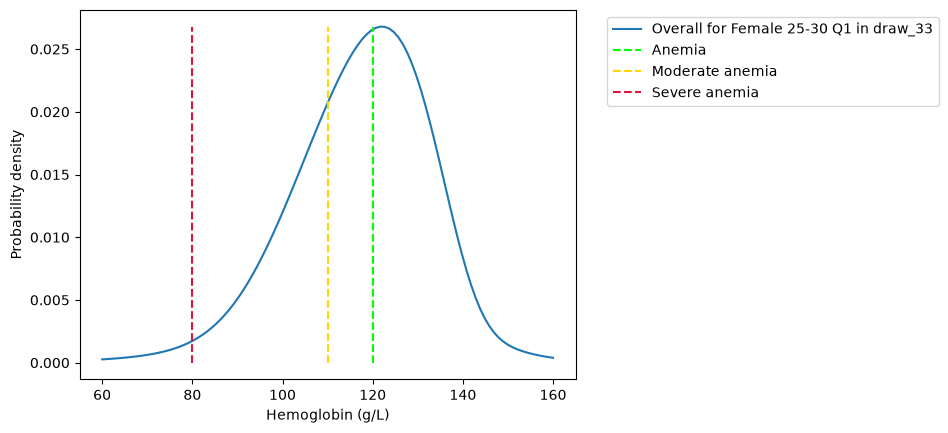

In [83]:
plot_example_distributions({"Overall": hemoglobin_distributions_by_age_sex_quintile})

In [84]:
# Assumption: non-iron-responsive anemias have same distribution of hemoglobin
# as iron-responsive anemias
non_iron_responsive_hemoglobin_distributions = truncate_distributions(
    hemoglobin_distributions_by_age_sex_quintile,
    truncate_max=hgb_info.hgb_upper_mild,
)

In [85]:
# Use even more wiggle room, as the issues in the previous check are "magnified"!
# NOTE: max_tolerance raised from 0.10 to 0.15 for model2.6.2.
# With the new GBD hemoglobin draws (release_id=33, from #72), India/rice max error went from 0.090 to 0.123.
# TODO: Check with research why the error increased for India/rice, then revisit this tolerance.
test_pdfs_cdfs_consistency(
    non_iron_responsive_hemoglobin_distributions,
    mean_tolerance=0.01,
    max_tolerance=0.15,
)

count    3.069000e+03
mean     4.022776e-04
std      7.969820e-04
min     -1.971757e-07
25%      1.254866e-05
50%      1.105458e-04
75%      3.889366e-04
max      1.115584e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.076712   0.5      1                draw_226   -1.971757e-07
Female  0.076712   0.5      1                draw_231   -1.840020e-07
Male    0.076712   0.5      4                draw_245   -1.528669e-07
                            2                draw_199   -1.422441e-07
Female  0.076712   0.5      4                draw_25    -1.372409e-07
                                                             ...     
Male    70.000000  75.0     1                draw_207    5.964277e-03
        0.500000   1.0      1                draw_194    5.987226e-03
                            5                draw_194    6.095715e-03
        95.000000  125.0    3                draw_76     9.171551e-03
        70.000000  75.0     5                draw_205    1.115584e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.000350
std         0.000799
min        -0.000206
25%        -0.000011
50%         0.000055
75%         0.000334
max         0.011134
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      2                draw_211   -0.000206
        0.076712   0.5      3                draw_192   -0.000201
        0.500000   1.0      3                draw_53    -0.000183
Female  0.076712   0.5      4                draw_25    -0.000178
Male    0.076712   0.5      2                draw_222   -0.000176
                                                           ...   
        70.000000  75.0     1                draw_207    0.005937
        0.500000   1.0      1                draw_194    0.005964
                            5                draw_194    0.006066
        95.000000  125.0    3                draw_76     0.009151
        70.000000  75.0     5                draw_205    0.011134
Length: 3069, dtype: float64

count    3069.000000
mean       -0.002116
std         0.002570
min        -0.014302
25%        -0.004035
50%        -0.001717
75%        -0.000053
max         0.011141
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  10.0       15.0     5                draw_19    -0.014302
Male    10.0       15.0     5                draw_215   -0.013857
                                             draw_26    -0.012514
                            1                draw_21    -0.012196
Female  90.0       95.0     5                draw_107   -0.012182
                                                           ...   
Male    70.0       75.0     1                draw_29     0.005577
        80.0       85.0     3                draw_29     0.005692
        70.0       75.0     1                draw_207    0.005945
        95.0       125.0    3                draw_76     0.009163
        70.0       75.0     5                draw_205    0.011141
Length: 3069, dtype: float64

count    3069.000000
mean       -0.005764
std         0.006260
min        -0.123444
25%        -0.007536
50%        -0.004723
75%        -0.003005
max         0.007528
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.0        0.019178    3                draw_105   -0.123444
                             2                draw_66    -0.112885
                             4                draw_158   -0.094849
                             3                draw_43    -0.089126
                             4                draw_240   -0.083620
                                                            ...   
      1.0        2.000000    5                draw_194    0.003745
      0.5        1.000000    1                draw_194    0.004608
                             5                draw_194    0.004635
      95.0       125.000000  3                draw_76     0.005713
      70.0       75.000000   5                draw_205    0.007528
Length: 3069, dtype: float64

count    3069.000000
mean       -0.005764
std         0.006260
min        -0.123444
25%        -0.007536
50%        -0.004723
75%        -0.003005
max         0.007528
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.0        0.019178    3                draw_105   -0.123444
                             2                draw_66    -0.112885
                             4                draw_158   -0.094849
                             3                draw_43    -0.089126
                             4                draw_240   -0.083620
                                                            ...   
      1.0        2.000000    5                draw_194    0.003745
      0.5        1.000000    1                draw_194    0.004608
                             5                draw_194    0.004635
      95.0       125.000000  3                draw_76     0.005713
      70.0       75.000000   5                draw_205    0.007528
Length: 3069, dtype: float64

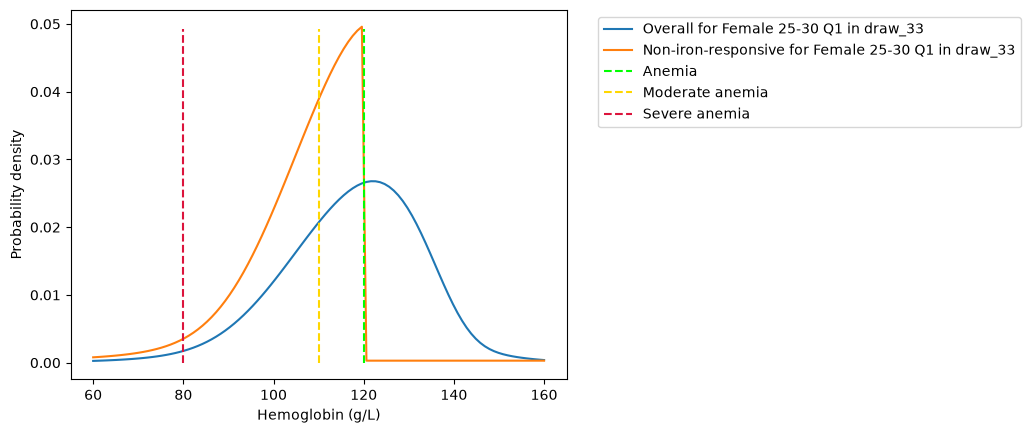

In [86]:
plot_example_distributions(
    {
        "Overall": hemoglobin_distributions_by_age_sex_quintile,
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
    }
)

In [87]:
gbd_hemoglobin_distributions = distributions_from_mean_sd(
    gbd_hgb_mean, gbd_hgb_sd.loc[gbd_hgb_mean.index]
)

In [88]:
gbd_anemia_prevalence = gbd_hemoglobin_distributions.cdfs(
    thresholds.hgb_upper_mild.reindex(gbd_hgb_mean.index)
)
gbd_anemia_prevalence

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.577890
                               draw_1      0.756433
                               draw_2      0.734475
                               draw_3      0.806079
                               draw_4      0.782396
                                             ...   
Male    95.0       125.000000  draw_245    0.502022
                               draw_246    0.553886
                               draw_247    0.563258
                               draw_248    0.847043
                               draw_249    0.422507
Length: 12500, dtype: float64

In [89]:
non_iron_responsive_anemia_proportion = (
    non_iron_responsive_prevalence / gbd_anemia_prevalence
)
non_iron_responsive_anemia_proportion

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.067292
                               draw_1      0.070236
                               draw_2      0.052360
                               draw_3      0.051454
                               draw_4      0.062197
                                             ...   
Male    95.0       125.000000  draw_245    0.126550
                               draw_246    0.069504
                               draw_247    0.087366
                               draw_248    0.057882
                               draw_249    0.079752
Length: 12500, dtype: float64

In [90]:
non_iron_responsive_anemia_proportion

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.067292
                               draw_1      0.070236
                               draw_2      0.052360
                               draw_3      0.051454
                               draw_4      0.062197
                                             ...   
Male    95.0       125.000000  draw_245    0.126550
                               draw_246    0.069504
                               draw_247    0.087366
                               draw_248    0.057882
                               draw_249    0.079752
Length: 12500, dtype: float64

In [91]:
hemoglobin_distributions_by_age_sex_quintile.cdfs(hgb_info.hgb_upper_mild)

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      0.633889
                                                draw_1      0.799685
                                                draw_2      0.792642
                                                draw_3      0.889768
                                                draw_4      0.844064
                                                              ...   
Male    95.0       125.000000  5                draw_245    0.462280
                                                draw_246    0.520931
                                                draw_247    0.509208
                                                draw_248    0.803982
                                                draw_249    0.389942
Length: 62500, dtype: float64

In [92]:
non_iron_responsive_anemia_prevalence_by_age_sex_quintile = (
    (
        non_iron_responsive_anemia_proportion
        * hemoglobin_distributions_by_age_sex_quintile.cdfs(hgb_info.hgb_upper_mild)
    )
    .reorder_levels(hgb_info.index.names)
    .reindex(hgb_info.index)
)
non_iron_responsive_anemia_prevalence_by_age_sex_quintile

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      0.042656
                                                draw_1      0.056166
                                                draw_2      0.041503
                                                draw_3      0.045782
                                                draw_4      0.052499
                                                              ...   
Male    95.0       125.000000  5                draw_245    0.058501
                                                draw_246    0.036207
                                                draw_247    0.044488
                                                draw_248    0.046536
                                                draw_249    0.031099
Length: 62500, dtype: float64

In [93]:
iron_responsive_distributions = delete_from_mixture_distributions(
    hemoglobin_distributions_by_age_sex_quintile,
    non_iron_responsive_hemoglobin_distributions,
    non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
)

In [94]:
test_pdfs_cdfs_consistency(
    iron_responsive_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.597278e-04
std      3.034194e-04
min     -1.448559e-07
25%      5.544017e-06
50%      4.400367e-05
75%      1.697211e-04
max      3.844510e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -1.448559e-07
Male    0.076712   0.5      1                draw_226   -1.427599e-07
                            2                draw_199   -1.120324e-07
Female  0.076712   0.5      4                draw_25    -1.012067e-07
Male    0.076712   0.5      3                draw_192   -9.907145e-08
                                                             ...     
        1.000000   2.0      5                draw_194    2.514999e-03
        0.500000   1.0      5                draw_194    2.662645e-03
                            1                draw_194    2.893074e-03
        70.000000  75.0     5                draw_205    3.719025e-03
        95.000000  125.0    3                draw_76     3.844510e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000134
std         0.000306
min        -0.000183
25%        -0.000005
50%         0.000018
75%         0.000143
max         0.003836
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      2                draw_211   -0.000183
        0.076712   0.5      3                draw_192   -0.000170
        0.500000   1.0      3                draw_53    -0.000169
Female  0.076712   0.5      2                draw_222   -0.000150
Male    0.076712   0.5      2                draw_222   -0.000140
                                                           ...   
        1.000000   2.0      5                draw_194    0.002502
        0.500000   1.0      5                draw_194    0.002650
                            1                draw_194    0.002882
        70.000000  75.0     5                draw_205    0.003712
        95.000000  125.0    3                draw_76     0.003836
Length: 3069, dtype: float64

count    3069.000000
mean        0.000355
std         0.000388
min        -0.000868
25%         0.000017
50%         0.000341
75%         0.000520
max         0.003841
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_219   -0.000868
Female  0.019178   0.076712    5                draw_99    -0.000828
                               4                draw_99    -0.000658
                               5                draw_215   -0.000557
Male    60.000000  65.000000   1                draw_1     -0.000425
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002594
        0.500000   1.000000    5                draw_194    0.002727
                               1                draw_194    0.002968
        70.000000  75.000000   5                draw_205    0.003714
        95.000000  125.000000  3                draw_76     0.003841
Length: 3069, dtype: float64

count    3069.000000
mean        0.000572
std         0.000493
min         0.000012
25%         0.000343
50%         0.000494
75%         0.000673
max         0.011389
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99     0.000012
Female  0.019178   0.076712    1                draw_165    0.000023
        1.000000   2.000000    1                draw_222    0.000053
Male    0.019178   0.076712    4                draw_219    0.000061
Female  0.076712   0.500000    2                draw_222    0.000063
                                                              ...   
Male    95.000000  125.000000  3                draw_76     0.004051
        0.000000   0.019178    3                draw_43     0.005456
                                                draw_105    0.009125
                               2                draw_66     0.010723
                               1                draw_7      0.011389
Length: 3069, dtype: float64

count    3069.000000
mean        0.000546
std         0.000482
min         0.000012
25%         0.000334
50%         0.000455
75%         0.000636
max         0.010793
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99     0.000012
Female  0.019178   0.076712    1                draw_165    0.000023
        1.000000   2.000000    1                draw_222    0.000053
Male    0.019178   0.076712    4                draw_219    0.000061
Female  0.076712   0.500000    2                draw_222    0.000063
                                                              ...   
Male    95.000000  125.000000  3                draw_76     0.004045
        0.000000   0.019178    3                draw_43     0.006017
                               2                draw_66     0.008279
                               3                draw_105    0.010742
                               1                draw_7      0.010793
Length: 3069, dtype: float64

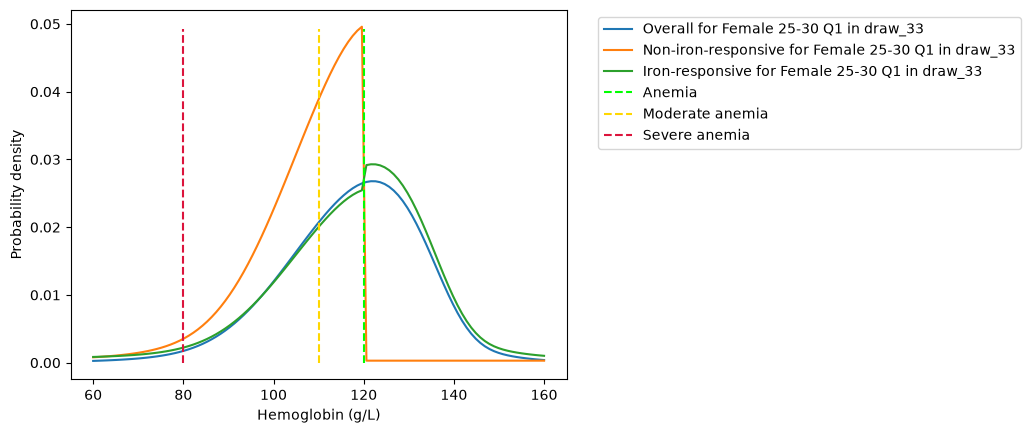

In [95]:
plot_example_distributions(
    {
        "Overall": hemoglobin_distributions_by_age_sex_quintile,
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive": iron_responsive_distributions,
    }
)

In [96]:
# NOTE: this decomposition, like what we do for wealth quintile above,
# is not exact -- we pretend that these two distributions would mix
# to the overall iron-responsive distribution, but they wouldn't.
# Here, we delete baseline coverage baked into the GBD 2021 distribution
# to get the without-fortification distribution.
# Also note that this and the next shift both assume that the hemoglobin effect among
# the responsive is a fixed value without individual-level variation.
iron_responsive_without_fortification_distributions = shift_distributions(
    iron_responsive_distributions,
    -effective_coverage_2021 * hemoglobin_effect_among_responsive.align(hgb_info)[0],
)

In [97]:
test_pdfs_cdfs_consistency(
    iron_responsive_without_fortification_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.602024e-04
std      3.041552e-04
min     -1.460236e-07
25%      5.571805e-06
50%      4.415992e-05
75%      1.702684e-04
max      3.851714e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -1.460236e-07
Male    0.076712   0.5      1                draw_226   -1.438055e-07
                            2                draw_199   -1.129601e-07
Female  0.076712   0.5      4                draw_25    -1.018967e-07
Male    0.076712   0.5      3                draw_192   -9.973011e-08
                                                             ...     
        1.000000   2.0      5                draw_194    2.520627e-03
        0.500000   1.0      5                draw_194    2.668339e-03
                            1                draw_194    2.899520e-03
        70.000000  75.0     5                draw_205    3.725601e-03
        95.000000  125.0    3                draw_76     3.851714e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000134
std         0.000306
min        -0.000183
25%        -0.000005
50%         0.000018
75%         0.000144
max         0.003843
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      2                draw_211   -0.000183
        0.076712   0.5      3                draw_192   -0.000171
        0.500000   1.0      3                draw_53    -0.000169
Female  0.076712   0.5      2                draw_222   -0.000151
Male    0.076712   0.5      2                draw_222   -0.000141
                                                           ...   
        1.000000   2.0      5                draw_194    0.002508
        0.500000   1.0      5                draw_194    0.002655
                            1                draw_194    0.002888
        70.000000  75.0     5                draw_205    0.003718
        95.000000  125.0    3                draw_76     0.003843
Length: 3069, dtype: float64

count    3069.000000
mean        0.000459
std         0.000463
min        -0.000857
25%         0.000017
50%         0.000457
75%         0.000690
max         0.003848
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_219   -0.000857
Female  0.019178   0.076712    5                draw_99    -0.000827
                               4                draw_99    -0.000652
                               5                draw_215   -0.000557
Male    60.000000  65.000000   1                draw_1     -0.000426
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002650
        0.500000   1.000000    5                draw_194    0.002779
                               1                draw_194    0.003024
        70.000000  75.000000   5                draw_205    0.003721
        95.000000  125.000000  3                draw_76     0.003848
Length: 3069, dtype: float64

count    3069.000000
mean        0.000749
std         0.000564
min         0.000015
25%         0.000490
50%         0.000658
75%         0.000887
max         0.013347
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99     0.000015
Female  0.019178   0.076712    1                draw_165    0.000029
Male    0.019178   0.076712    4                draw_219    0.000075
Female  1.000000   2.000000    1                draw_222    0.000089
        0.019178   0.076712    4                draw_99     0.000094
                                                              ...   
Male    95.000000  125.000000  3                draw_76     0.004129
        0.000000   0.019178    3                draw_43     0.006556
                                                draw_105    0.011129
                               2                draw_66     0.012335
                               1                draw_7      0.013347
Length: 3069, dtype: float64

count    3069.000000
mean        0.000722
std         0.000553
min         0.000015
25%         0.000475
50%         0.000627
75%         0.000849
max         0.012729
dtype: float64


sex     age_start  age_end   wealth_quintile  draw    
Male    0.019178   0.076712  1                draw_99     0.000015
Female  0.019178   0.076712  1                draw_165    0.000029
Male    0.019178   0.076712  4                draw_219    0.000075
Female  0.000000   0.019178  1                draw_229    0.000081
        1.000000   2.000000  1                draw_222    0.000089
                                                            ...   
Male    0.000000   0.019178  4                draw_158    0.004634
                             3                draw_43     0.007088
                             2                draw_66     0.009761
                             1                draw_7      0.012701
                             3                draw_105    0.012729
Length: 3069, dtype: float64

In [98]:
iron_responsive_with_fortification_distributions = shift_distributions(
    iron_responsive_without_fortification_distributions,
    hemoglobin_effect_among_responsive.align(hgb_info)[0],
)

In [99]:
test_pdfs_cdfs_consistency(
    iron_responsive_with_fortification_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.564402e-04
std      2.980228e-04
min     -4.945527e-08
25%      5.440067e-06
50%      4.290961e-05
75%      1.656864e-04
max      3.794660e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -4.945527e-08
Male    0.076712   0.5      2                draw_199   -4.204789e-08
                            3                draw_47    -3.091807e-08
                            2                draw_47    -2.794280e-08
Female  0.076712   0.5      5                draw_87    -2.666082e-08
                                                             ...     
Male    1.000000   2.0      5                draw_194    2.472969e-03
        0.500000   1.0      5                draw_194    2.619719e-03
                            1                draw_194    2.846120e-03
        70.000000  75.0     5                draw_205    3.671802e-03
        95.000000  125.0    3                draw_76     3.794660e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000137
std         0.000298
min        -0.000146
25%        -0.000001
50%         0.000024
75%         0.000144
max         0.003786
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_53    -0.000146
                            2                draw_211   -0.000125
Female  1.000000   2.0      1                draw_222   -0.000107
Male    0.076712   0.5      3                draw_192   -0.000106
        0.500000   1.0      3                draw_127   -0.000105
                                                           ...   
        1.000000   2.0      5                draw_194    0.002456
        0.500000   1.0      5                draw_194    0.002604
                            1                draw_194    0.002831
        70.000000  75.0     5                draw_205    0.003665
        95.000000  125.0    3                draw_76     0.003786
Length: 3069, dtype: float64

count    3069.000000
mean        0.000473
std         0.000469
min        -0.001030
25%         0.000009
50%         0.000479
75%         0.000727
max         0.003789
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99    -0.001030
                               4                draw_219   -0.000775
Female  0.019178   0.076712    4                draw_99    -0.000635
                               3                draw_56    -0.000519
Male    0.019178   0.076712    3                draw_165   -0.000506
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002653
        0.500000   1.000000    5                draw_194    0.002778
                               1                draw_194    0.003019
        70.000000  75.000000   5                draw_205    0.003665
        95.000000  125.000000  3                draw_76     0.003789
Length: 3069, dtype: float64

count    3069.000000
mean        0.000768
std         0.000404
min        -0.001853
25%         0.000540
50%         0.000734
75%         0.000969
max         0.004128
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.000000   0.019178    2                draw_66    -0.001853
                             1                draw_7     -0.000962
                             3                draw_43    -0.000833
                             2                draw_138   -0.000727
                             5                draw_74    -0.000645
                                                            ...   
      0.019178   0.076712    4                draw_98     0.003026
      0.500000   1.000000    1                draw_194    0.003030
      60.000000  65.000000   1                draw_1      0.003067
      70.000000  75.000000   5                draw_205    0.004101
      95.000000  125.000000  3                draw_76     0.004128
Length: 3069, dtype: float64

count    3069.000000
mean        0.000796
std         0.000587
min         0.000017
25%         0.000544
50%         0.000714
75%         0.000945
max         0.014915
dtype: float64


sex     age_start  age_end   wealth_quintile  draw    
Male    0.019178   0.076712  1                draw_99     0.000017
Female  0.019178   0.076712  1                draw_165    0.000035
Male    0.019178   0.076712  4                draw_219    0.000089
Female  0.000000   0.019178  1                draw_229    0.000090
                                              draw_148    0.000092
                                                            ...   
Male    0.000000   0.019178  4                draw_158    0.005368
                             3                draw_43     0.007638
                             2                draw_66     0.009912
                             3                draw_105    0.014395
                             1                draw_7      0.014915
Length: 3069, dtype: float64

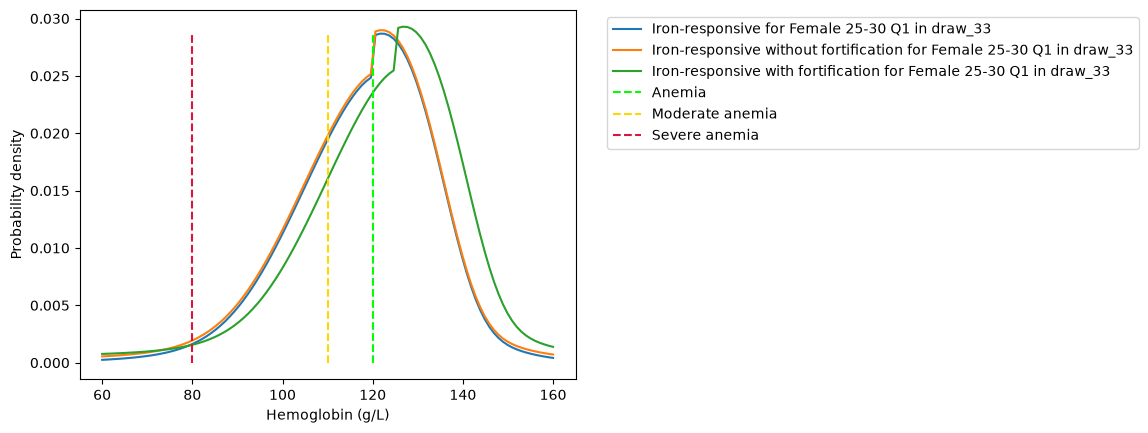

In [100]:
plot_example_distributions(
    {
        "Iron-responsive": iron_responsive_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
    }
)

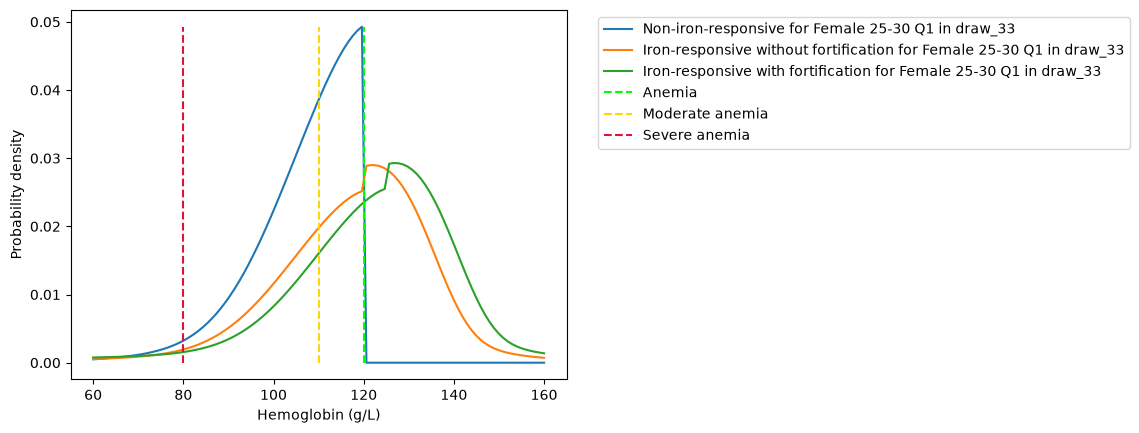

In [101]:
plot_example_distributions(
    {
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
    }
)

In [102]:
zero_fort_scenario_distributions = mix_distributions(
    [
        (
            non_iron_responsive_hemoglobin_distributions,
            non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
        ),
        (
            iron_responsive_without_fortification_distributions,
            1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
        ),
    ]
)

In [103]:
test_pdfs_cdfs_consistency(
    zero_fort_scenario_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.753771e-04
std      3.358814e-04
min     -1.480935e-07
25%      5.986098e-06
50%      4.764679e-05
75%      1.849896e-04
max      4.228778e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -1.480935e-07
Male    0.076712   0.5      1                draw_226   -1.464561e-07
                            2                draw_199   -1.147870e-07
Female  0.076712   0.5      4                draw_25    -1.031590e-07
Male    0.076712   0.5      3                draw_192   -1.005881e-07
                                                             ...     
        1.000000   2.0      5                draw_194    2.611287e-03
        0.500000   1.0      5                draw_194    2.773687e-03
                            1                draw_194    3.004167e-03
        95.000000  125.0    3                draw_76     4.124259e-03
        70.000000  75.0     5                draw_205    4.228778e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000148
std         0.000338
min        -0.000185
25%        -0.000006
50%         0.000021
75%         0.000156
max         0.004221
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      2                draw_211   -0.000185
        0.076712   0.5      3                draw_192   -0.000173
        0.500000   1.0      3                draw_53    -0.000170
Female  0.076712   0.5      2                draw_222   -0.000152
Male    0.076712   0.5      2                draw_222   -0.000142
                                                           ...   
        1.000000   2.0      5                draw_194    0.002598
        0.500000   1.0      5                draw_194    0.002760
                            1                draw_194    0.002993
        95.000000  125.0    3                draw_76     0.004115
        70.000000  75.0     5                draw_205    0.004221
Length: 3069, dtype: float64

count    3069.000000
mean        0.000298
std         0.000372
min        -0.000858
25%         0.000019
50%         0.000270
75%         0.000399
max         0.004223
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_219   -0.000858
Female  0.019178   0.076712    5                draw_99    -0.000828
                               4                draw_99    -0.000652
                               5                draw_215   -0.000562
Male    60.000000  65.000000   1                draw_1     -0.000480
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002688
        0.500000   1.000000    5                draw_194    0.002836
                               1                draw_194    0.003078
        95.000000  125.000000  3                draw_76     0.004120
        70.000000  75.000000   5                draw_205    0.004223
Length: 3069, dtype: float64

count    3069.000000
mean        0.000366
std         0.000335
min        -0.000128
25%         0.000203
50%         0.000278
75%         0.000385
max         0.004332
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.000000   0.019178    4                draw_240   -0.000128
                                                draw_158   -0.000107
        0.019178   0.076712    1                draw_99     0.000003
Female  0.019178   0.076712    1                draw_165    0.000006
Male    0.019178   0.076712    4                draw_219    0.000013
                                                              ...   
        0.500000   1.000000    5                draw_194    0.002843
                               1                draw_194    0.003072
        0.000000   0.019178    2                draw_66     0.003779
        95.000000  125.000000  3                draw_76     0.004210
        70.000000  75.000000   5                draw_205    0.004332
Length: 3069, dtype: float64

count    3069.000000
mean        0.000341
std         0.000330
min         0.000003
25%         0.000182
50%         0.000242
75%         0.000363
max         0.004340
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99     0.000003
Female  0.019178   0.076712    1                draw_165    0.000006
        0.000000   0.019178    1                draw_229    0.000010
Male    0.000000   0.019178    1                draw_107    0.000011
Female  0.000000   0.019178    1                draw_148    0.000011
                                                              ...   
Male    80.000000  85.000000   3                draw_29     0.002671
        0.500000   1.000000    5                draw_194    0.002828
                               1                draw_194    0.003063
        95.000000  125.000000  3                draw_76     0.004204
        70.000000  75.000000   5                draw_205    0.004340
Length: 3069, dtype: float64

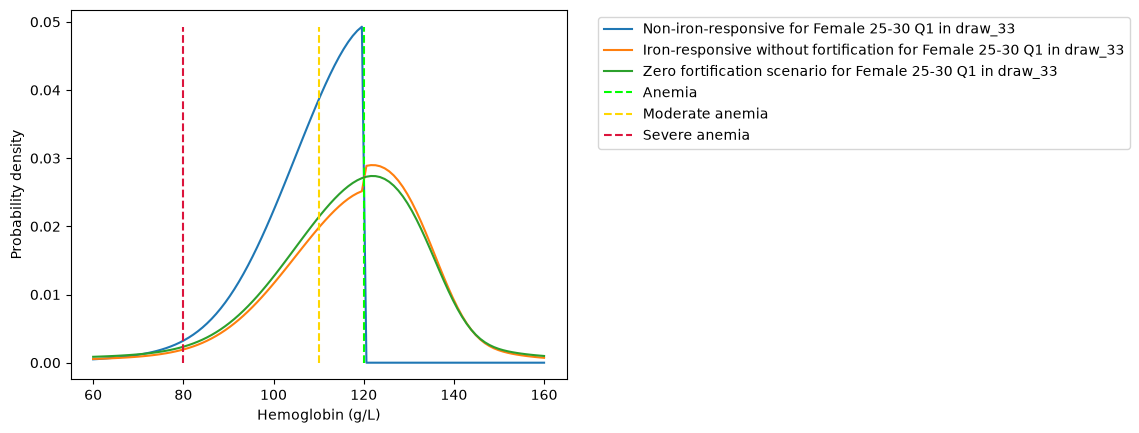

In [104]:
plot_example_distributions(
    {
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Zero fortification scenario": zero_fort_scenario_distributions,
    }
)

In [105]:
baseline_scenario_distributions = mix_distributions(
    [
        (
            non_iron_responsive_hemoglobin_distributions,
            non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
        ),
        (
            iron_responsive_without_fortification_distributions,
            (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
            * (1 - effective_coverage_baseline),
        ),
        (
            iron_responsive_with_fortification_distributions,
            (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
            * effective_coverage_baseline,
        ),
    ]
)

In [106]:
test_pdfs_cdfs_consistency(
    baseline_scenario_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.753383e-04
std      3.358188e-04
min     -1.471569e-07
25%      5.985371e-06
50%      4.763583e-05
75%      1.849567e-04
max      4.228208e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -1.471569e-07
Male    0.076712   0.5      1                draw_226   -1.451858e-07
                            2                draw_199   -1.141158e-07
Female  0.076712   0.5      4                draw_25    -1.014900e-07
Male    0.076712   0.5      3                draw_192   -9.796970e-08
                                                             ...     
        1.000000   2.0      5                draw_194    2.610826e-03
        0.500000   1.0      5                draw_194    2.773214e-03
                            1                draw_194    3.003636e-03
        95.000000  125.0    3                draw_76     4.123644e-03
        70.000000  75.0     5                draw_205    4.228208e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000148
std         0.000338
min        -0.000184
25%        -0.000006
50%         0.000021
75%         0.000156
max         0.004220
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      2                draw_211   -0.000184
        0.076712   0.5      3                draw_192   -0.000172
        0.500000   1.0      3                draw_53    -0.000170
Female  0.076712   0.5      2                draw_222   -0.000150
Male    0.076712   0.5      2                draw_222   -0.000141
                                                           ...   
        1.000000   2.0      5                draw_194    0.002597
        0.500000   1.0      5                draw_194    0.002760
                            1                draw_194    0.002992
        95.000000  125.0    3                draw_76     0.004115
        70.000000  75.0     5                draw_205    0.004220
Length: 3069, dtype: float64

count    3069.000000
mean        0.000298
std         0.000372
min        -0.000857
25%         0.000019
50%         0.000270
75%         0.000399
max         0.004223
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_219   -0.000857
Female  0.019178   0.076712    5                draw_99    -0.000825
                               4                draw_99    -0.000652
                               5                draw_215   -0.000561
Male    60.000000  65.000000   1                draw_1     -0.000478
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002688
        0.500000   1.000000    5                draw_194    0.002836
                               1                draw_194    0.003078
        95.000000  125.000000  3                draw_76     0.004120
        70.000000  75.000000   5                draw_205    0.004223
Length: 3069, dtype: float64

count    3069.000000
mean        0.000367
std         0.000335
min        -0.000167
25%         0.000204
50%         0.000279
75%         0.000386
max         0.004332
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.000000   0.019178    4                draw_240   -0.000167
                                                draw_158   -0.000145
        0.019178   0.076712    1                draw_99     0.000003
Female  0.019178   0.076712    1                draw_165    0.000006
Male    0.019178   0.076712    4                draw_219    0.000013
                                                              ...   
        0.500000   1.000000    5                draw_194    0.002843
                               1                draw_194    0.003072
        0.000000   0.019178    2                draw_66     0.003646
        95.000000  125.000000  3                draw_76     0.004210
        70.000000  75.000000   5                draw_205    0.004332
Length: 3069, dtype: float64

count    3069.000000
mean        0.000342
std         0.000330
min         0.000003
25%         0.000184
50%         0.000244
75%         0.000363
max         0.004340
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99     0.000003
Female  0.019178   0.076712    1                draw_165    0.000006
        0.000000   0.019178    1                draw_229    0.000010
                                                draw_148    0.000011
Male    0.000000   0.019178    1                draw_107    0.000011
                                                              ...   
        80.000000  85.000000   3                draw_29     0.002671
        0.500000   1.000000    5                draw_194    0.002828
                               1                draw_194    0.003063
        95.000000  125.000000  3                draw_76     0.004204
        70.000000  75.000000   5                draw_205    0.004340
Length: 3069, dtype: float64

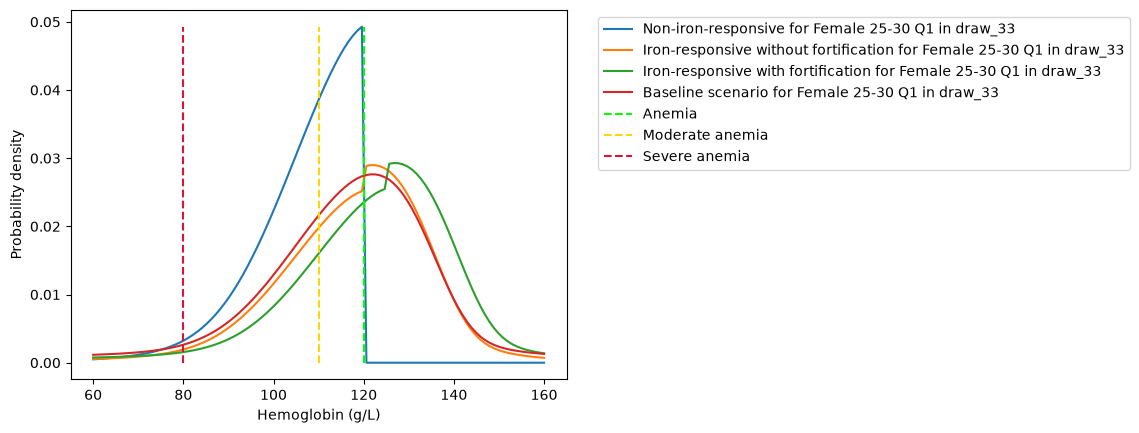

In [107]:
plot_example_distributions(
    {
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
        "Baseline scenario": baseline_scenario_distributions,
    }
)

In [108]:
intervention_scenario_distributions = {}

for intervention_scenario in intervention_scenarios:
    effective_coverage_for_scenario = (
        effective_coverage_intervention[
            effective_coverage_intervention.index.get_level_values("scenario")
            == intervention_scenario
        ]
        .droplevel("scenario")
        .reindex(hgb_info.index)
    )
    intervention_scenario_distributions[intervention_scenario] = mix_distributions(
        [
            (
                non_iron_responsive_hemoglobin_distributions,
                non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
            ),
            (
                iron_responsive_without_fortification_distributions,
                (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
                * (1 - effective_coverage_for_scenario),
            ),
            (
                iron_responsive_with_fortification_distributions,
                (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
                * effective_coverage_for_scenario,
            ),
        ]
    )

In [109]:
for _, dists in intervention_scenario_distributions.items():
    test_pdfs_cdfs_consistency(
        dists,
        mean_tolerance=0.005,
        max_tolerance=0.05,
    )

count    3.069000e+03
mean     1.744194e-04
std      3.343338e-04
min     -1.249605e-07
25%      5.968134e-06
50%      4.737621e-05
75%      1.840532e-04
max      4.214692e-03
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  0.076712   0.5      1                draw_231   -1.249605e-07
Male    0.076712   0.5      1                draw_226   -1.150796e-07
                            2                draw_199   -9.820826e-08
                            4                draw_245   -7.019661e-08
                            3                draw_47    -6.887025e-08
                                                             ...     
        1.000000   2.0      5                draw_194    2.599888e-03
        0.500000   1.0      5                draw_194    2.762015e-03
                            1                draw_194    2.991037e-03
        95.000000  125.0    3                draw_76     4.109065e-03
        70.000000  75.0     5                draw_205    4.214692e-03
Length: 3069, dtype: float64

count    3069.000000
mean        0.000148
std         0.000336
min        -0.000171
25%        -0.000005
50%         0.000022
75%         0.000156
max         0.004207
dtype: float64


sex   age_start  age_end  wealth_quintile  draw    
Male  0.500000   1.0      2                draw_211   -0.000171
                          3                draw_53    -0.000165
      0.076712   0.5      3                draw_192   -0.000157
                          2                draw_222   -0.000131
      0.500000   1.0      3                draw_127   -0.000127
                                                         ...   
      1.000000   2.0      5                draw_194    0.002586
      0.500000   1.0      5                draw_194    0.002748
                          1                draw_194    0.002979
      95.000000  125.0    3                draw_76     0.004100
      70.000000  75.0     5                draw_205    0.004207
Length: 3069, dtype: float64

count    3069.000000
mean        0.000302
std         0.000372
min        -0.000839
25%         0.000017
50%         0.000280
75%         0.000402
max         0.004209
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_219   -0.000839
Female  0.019178   0.076712    5                draw_99    -0.000751
                               4                draw_99    -0.000648
                               5                draw_215   -0.000516
Male    60.000000  65.000000   1                draw_1     -0.000441
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002689
        0.500000   1.000000    5                draw_194    0.002836
                               1                draw_194    0.003077
        95.000000  125.000000  3                draw_76     0.004105
        70.000000  75.000000   5                draw_205    0.004209
Length: 3069, dtype: float64

count    3069.000000
mean        0.000373
std         0.000338
min        -0.002272
25%         0.000224
50%         0.000297
75%         0.000399
max         0.004332
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.0        0.019178    3                draw_105   -0.002272
                                              draw_43    -0.001224
                             4                draw_240   -0.001106
                                              draw_158   -0.001057
                             2                draw_138   -0.001006
                                                            ...   
      1.0        2.000000    5                draw_194    0.002683
      0.5        1.000000    5                draw_194    0.002846
                             1                draw_194    0.003075
      95.0       125.000000  3                draw_76     0.004210
      70.0       75.000000   5                draw_205    0.004332
Length: 3069, dtype: float64

count    3069.000000
mean        0.000360
std         0.000329
min         0.000003
25%         0.000206
50%         0.000266
75%         0.000380
max         0.004342
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    1                draw_99     0.000003
Female  0.019178   0.076712    1                draw_165    0.000007
        0.000000   0.019178    1                draw_148    0.000012
                                                draw_229    0.000012
Male    0.000000   0.019178    2                draw_53     0.000015
                                                              ...   
        1.000000   2.000000    5                draw_194    0.002673
        0.500000   1.000000    5                draw_194    0.002829
                               1                draw_194    0.003064
        95.000000  125.000000  3                draw_76     0.004206
        70.000000  75.000000   5                draw_205    0.004342
Length: 3069, dtype: float64

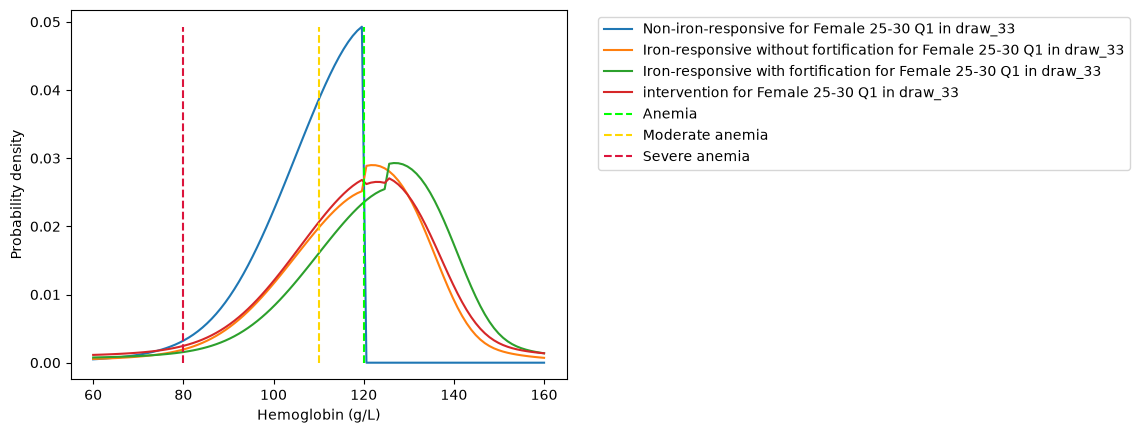

In [110]:
for intervention_scenario in intervention_scenarios:
    plot_example_distributions(
        {
            "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
            "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
            "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
            intervention_scenario: intervention_scenario_distributions[
                intervention_scenario
            ],
        }
    )
    plt.show()

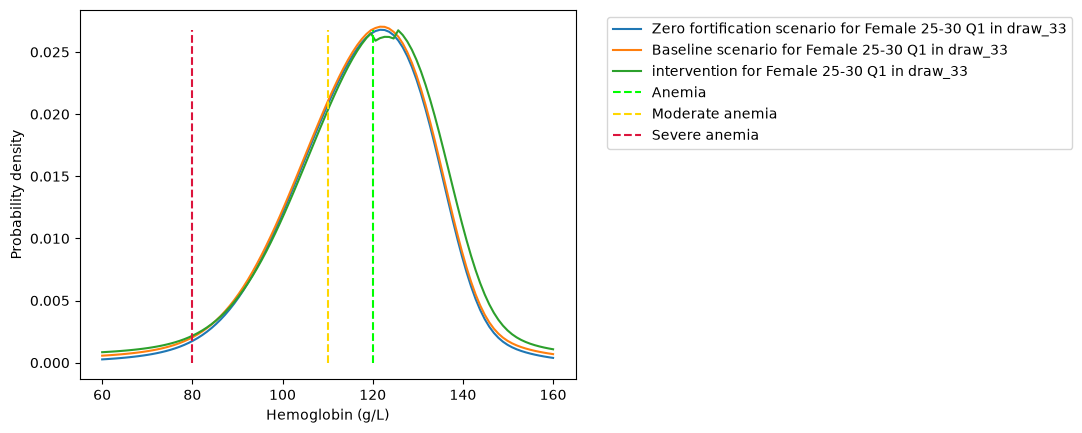

In [111]:
plot_example_distributions(
    {
        "Zero fortification scenario": zero_fort_scenario_distributions,
        "Baseline scenario": baseline_scenario_distributions,
        **intervention_scenario_distributions,
    }
)

In [112]:
def anemia_by_severity_from_distributions(distributions: Distributions):
    result = pd.DataFrame(index=distributions.data_index)
    assert result.index.equals(hgb_info.index)

    result["severe"] = distributions.cdfs(
        hgb_info.hgb_upper_severe.copy()
    ) - distributions.cdfs(hgb_info.hgb_lower_severe.copy())
    result["moderate"] = (
        distributions.cdfs(hgb_info.hgb_upper_moderate.copy()) - result["severe"]
    )
    result["mild"] = (
        distributions.cdfs(hgb_info.hgb_upper_mild.copy())
        - result["moderate"]
        - result["severe"]
    )
    result["anemic"] = result["mild"] + result["moderate"] + result["severe"]

    assert (result >= 0).all().all()
    assert (result <= 1).all().all()
    return result

In [113]:
zero_fort_scenario_anemia_by_severity = anemia_by_severity_from_distributions(
    zero_fort_scenario_distributions
)
zero_fort_scenario_anemia_by_severity

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.017341  0.336177   
                                            draw_1    0.047619  0.495441   
                                            draw_2    0.014868  0.442346   
                                            draw_3    0.000808  0.333717   
                                            draw_4    0.008249  0.451905   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.009163  0.114912   
                                            draw_246  0.017982  0.164469   
                                            draw_247  0.002561  0.074589   
                                            draw_248  0.001543  0.115704   
                                            draw_249  0.017081  0.119635   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.281376  0.634894  
                                            draw_1    0.257388  0.800447  
                                            draw_2    0.336437  0.793651  
                                            draw_3    0.556510  0.891035  
                                            draw_4    0.384939  0.845094  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.339501  0.463576  
                                            draw_246  0.339647  0.522098  
                                            draw_247  0.433909  0.511059  
                                            draw_248  0.688738  0.805984  
                                            draw_249  0.254155  0.390872  

[62500 rows x 4 columns]

In [114]:
baseline_scenario_anemia_by_severity = anemia_by_severity_from_distributions(
    baseline_scenario_distributions
)
baseline_scenario_anemia_by_severity

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.017294  0.335471   
                                            draw_1    0.047486  0.494739   
                                            draw_2    0.014821  0.441369   
                                            draw_3    0.000805  0.332310   
                                            draw_4    0.008221  0.450753   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.009135  0.114512   
                                            draw_246  0.017926  0.163965   
                                            draw_247  0.002551  0.074230   
                                            draw_248  0.001535  0.115040   
                                            draw_249  0.017035  0.119286   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.281187  0.633952  
                                            draw_1    0.257461  0.799686  
                                            draw_2    0.336423  0.792613  
                                            draw_3    0.556328  0.889443  
                                            draw_4    0.385007  0.843981  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.338851  0.462498  
                                            draw_246  0.339151  0.521042  
                                            draw_247  0.432685  0.509466  
                                            draw_248  0.687254  0.803830  
                                            draw_249  0.253736  0.390057  

[62500 rows x 4 columns]

In [115]:
intervention_scenarios_anemia_by_severity = {}

for scenario, distributions in intervention_scenario_distributions.items():
    anemia_by_severity = anemia_by_severity_from_distributions(distributions)
    print(scenario)
    display(anemia_by_severity)
    intervention_scenarios_anemia_by_severity[scenario] = anemia_by_severity

intervention


severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.016168  0.318750   
                                            draw_1    0.044335  0.478092   
                                            draw_2    0.013710  0.418208   
                                            draw_3    0.000718  0.298956   
                                            draw_4    0.007562  0.423430   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.008463  0.105028   
                                            draw_246  0.016585  0.152021   
                                            draw_247  0.002303  0.065723   
                                            draw_248  0.001349  0.099324   
                                            draw_249  0.015933  0.110997   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.276712  0.611630  
                                            draw_1    0.259206  0.781633  
                                            draw_2    0.336085  0.768003  
                                            draw_3    0.552033  0.851707  
                                            draw_4    0.386603  0.817596  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.323441  0.436932  
                                            draw_246  0.327395  0.496001  
                                            draw_247  0.403673  0.471699  
                                            draw_248  0.652102  0.752775  
                                            draw_249  0.243814  0.370744  

[62500 rows x 4 columns]

In [116]:
# Transform the intervention scenarios back from a dictionary to the scenario being a level
# in the MultiIndex, which is easier to work with now that we are out of function/distribution space.
intervention_scenarios_anemia_by_severity = pd.concat(
    [
        anemia_by_severity.assign(scenario=scenario).set_index("scenario", append=True)
        for scenario, anemia_by_severity in intervention_scenarios_anemia_by_severity.items()
    ]
)
intervention_scenarios_anemia_by_severity

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.016168   
                                            draw_1   intervention  0.044335   
                                            draw_2   intervention  0.013710   
                                            draw_3   intervention  0.000718   
                                            draw_4   intervention  0.007562   
...                                                                     ...   
Male   95.0      125.000000 5               draw_245 intervention  0.008463   
                                            draw_246 intervention  0.016585   
                                            draw_247 intervention  0.002303   
                                            draw_248 intervention  0.001349   
                                            draw_249 intervention  0.015933   

                                                                   moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.318750   
                                            draw_1   intervention  0.478092   
                                            draw_2   intervention  0.418208   
                                            draw_3   intervention  0.298956   
                                            draw_4   intervention  0.423430   
...                                                                     ...   
Male   95.0      125.000000 5               draw_245 intervention  0.105028   
                                            draw_246 intervention  0.152021   
                                            draw_247 intervention  0.065723   
                                            draw_248 intervention  0.099324   
                                            draw_249 intervention  0.110997   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.276712   
                                            draw_1   intervention  0.259206   
                                            draw_2   intervention  0.336085   
                                            draw_3   intervention  0.552033   
                                            draw_4   intervention  0.386603   
...                                                                     ...   
Male   95.0      125.000000 5               draw_245 intervention  0.323441   
                                            draw_246 intervention  0.327395   
                                            draw_247 intervention  0.403673   
                                            draw_248 intervention  0.652102   
                                            draw_249 intervention  0.243814   

                                                                     anemic  
sex    age_start age_end    wealth_quintile draw     scenario                
Female 0.0       0.019178   1               draw_0   intervention  0.611630  
                                            draw_1   intervention  0.781633  
                                            draw_2   intervention  0.768003  
                                            draw_3   intervention  0.851707  
                                            draw_4   intervention  0.817596  
...                                                                     ...  
Male   95.0      125.000000 5               draw_245 intervention  0.436932  
                                            draw_246 intervention  0.496001  
                                            draw_247 intervention  0.471699  
                                            draw_248 intervention  0.752775  
                                            draw_

In [117]:
zero_fort_scenario_anemia_by_severity - baseline_scenario_anemia_by_severity

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.000048  0.000706   
                                            draw_1    0.000133  0.000702   
                                            draw_2    0.000047  0.000977   
                                            draw_3    0.000004  0.001407   
                                            draw_4    0.000028  0.001153   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.000028  0.000400   
                                            draw_246  0.000057  0.000504   
                                            draw_247  0.000010  0.000359   
                                            draw_248  0.000008  0.000663   
                                            draw_249  0.000046  0.000350   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.000189  0.000942  
                                            draw_1   -0.000074  0.000762  
                                            draw_2    0.000014  0.001038  
                                            draw_3    0.000181  0.001592  
                                            draw_4   -0.000067  0.001113  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.000650  0.001079  
                                            draw_246  0.000496  0.001057  
                                            draw_247  0.001224  0.001594  
                                            draw_248  0.001483  0.002154  
                                            draw_249  0.000419  0.000815  

[62500 rows x 4 columns]

In [118]:
baseline_scenario_anemia_by_severity - intervention_scenarios_anemia_by_severity

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.001126   
                                            draw_1   intervention  0.003150   
                                            draw_10  intervention  0.005832   
                                            draw_100 intervention  0.000624   
                                            draw_101 intervention  0.000224   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.000156   
                                            draw_96  intervention  0.000930   
                                            draw_97  intervention  0.000169   
                                            draw_98  intervention  0.000021   
                                            draw_99  intervention  0.000036   

                                                                   moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.016721   
                                            draw_1   intervention  0.016647   
                                            draw_10  intervention  0.010612   
                                            draw_100 intervention  0.023850   
                                            draw_101 intervention  0.029999   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.014670   
                                            draw_96  intervention  0.006457   
                                            draw_97  intervention  0.004484   
                                            draw_98  intervention  0.001815   
                                            draw_99  intervention  0.009724   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.004476   
                                            draw_1   intervention -0.001745   
                                            draw_10  intervention -0.002303   
                                            draw_100 intervention  0.003841   
                                            draw_101 intervention  0.003150   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.036967   
                                            draw_96  intervention  0.008242   
                                            draw_97  intervention  0.022233   
                                            draw_98  intervention  0.037453   
                                            draw_99  intervention  0.053547   

                                                                     anemic  
sex    age_start age_end    wealth_quintile draw     scenario                
Female 0.0       0.019178   1               draw_0   intervention  0.022322  
                                            draw_1   intervention  0.018053  
                                            draw_10  intervention  0.014141  
                                            draw_100 intervention  0.028315  
                                            draw_101 intervention  0.033373  
...                                                                     ...  
Male   95.0      125.000000 5               draw_95  intervention  0.051793  
                                            draw_96  intervention  0.015629  
                                            draw_97  intervention  0.026885  
                                            draw_98  intervention  0.039289  
                                            draw_

<Axes: >

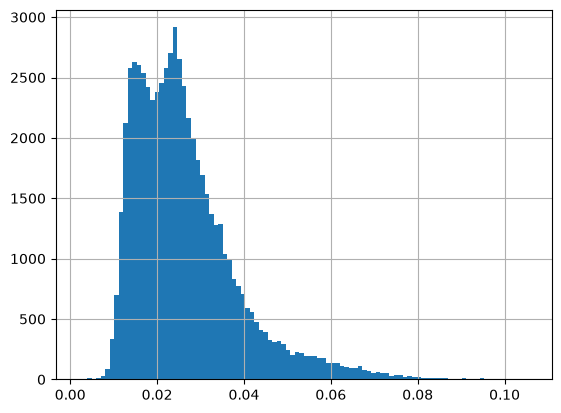

In [119]:
# We can see that in very rare cases, likely due to numerical instability, we get a negative impact
(
    baseline_scenario_anemia_by_severity - intervention_scenarios_anemia_by_severity
).anemic.hist(bins=100)

In [120]:
def anemia_by_severity_to_yld_rates(anemia_by_severity):
    disability_weights = pd.read_hdf(
        "/mnt/team/simulation_science/costeffectiveness/auxiliary_data/GBD_2021/02_processed_data/disability_weight/sequela/all/all.hdf"
    )
    disability_weights = (
        disability_weights[
            disability_weights.healthstate.isin(
                ["anemia_mild", "anemia_mod", "anemia_sev"]
            )
        ]
        .set_index("healthstate")
        .filter(like="draw_")
    )
    disability_weights.columns.name = "draw"
    disability_weights = (
        disability_weights.stack().rename("disability_weight").reset_index()
    )
    display(disability_weights)

    orig_index = anemia_by_severity.index
    anemia_by_severity = (
        anemia_by_severity.reset_index()
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_mild"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "mild_dw"}),
            validate="m:1",
        )
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_mod"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "moderate_dw"}),
            validate="m:1",
        )
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_sev"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "severe_dw"}),
            validate="m:1",
        )
    )

    anemia_by_severity["mild_yld_rate"] = (
        anemia_by_severity.mild * anemia_by_severity.mild_dw
    )
    anemia_by_severity["moderate_yld_rate"] = (
        anemia_by_severity.moderate * anemia_by_severity.moderate_dw
    )
    anemia_by_severity["severe_yld_rate"] = (
        anemia_by_severity.severe * anemia_by_severity.severe_dw
    )
    anemia_by_severity["anemic_yld_rate"] = (
        anemia_by_severity["mild_yld_rate"]
        + anemia_by_severity["moderate_yld_rate"]
        + anemia_by_severity["severe_yld_rate"]
    )

    return anemia_by_severity.set_index(orig_index.names).filter(like="yld_rate")

In [121]:
zero_fort_scenario_anemia_yld_rates = anemia_by_severity_to_yld_rates(
    zero_fort_scenario_anemia_by_severity
)
zero_fort_scenario_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw                      
Female 0.0       0.019178   1               draw_0         0.000681   
                                            draw_1         0.000817   
                                            draw_2         0.000889   
                                            draw_3         0.001717   
                                            draw_4         0.000710   
...                                                             ...   
Male   95.0      125.000000 5               draw_245       0.000823   
                                            draw_246       0.001035   
                                            draw_247       0.001200   
                                            draw_248       0.003777   
                                            draw_249       0.001353   

                                                      moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0             0.019935   
                                            draw_1             0.028275   
                                            draw_2             0.018665   
                                            draw_3             0.010407   
                                            draw_4             0.013510   
...                                                                 ...   
Male   95.0      125.000000 5               draw_245           0.005890   
                                            draw_246           0.008499   
                                            draw_247           0.003745   
                                            draw_248           0.006967   
                                            draw_249           0.008831   

                                                      severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw                        
Female 0.0       0.019178   1               draw_0           0.003450   
                                            draw_1           0.007640   
                                            draw_2           0.001861   
                                            draw_3           0.000068   
                                            draw_4           0.000842   
...                                                               ...   
Male   95.0      125.000000 5               draw_245         0.001543   
                                            draw_246         0.002611   
                                            draw_247         0.000388   
                                            draw_248         0.000200   
                                            draw_249         0.003227   

                                                      anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0           0.024066  
                                            draw_1           0.036731  
                                            draw_2           0.021416  
                                            draw_3           0.012193  
                                            draw_4           0.015062  
...                                                               ...  
Male   95.0      125.000000 5               draw_245         0.008256  
                                            draw_246         0.012145  
                                            draw_247         0.005332  
                                            draw_248         0.010943  
                                            draw_249         0.013411  

[62500 rows x 4 columns]

In [122]:
baseline_scenario_anemia_yld_rates = anemia_by_severity_to_yld_rates(
    baseline_scenario_anemia_by_severity
)
baseline_scenario_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw                      
Female 0.0       0.019178   1               draw_0         0.000681   
                                            draw_1         0.000817   
                                            draw_2         0.000889   
                                            draw_3         0.001716   
                                            draw_4         0.000710   
...                                                             ...   
Male   95.0      125.000000 5               draw_245       0.000821   
                                            draw_246       0.001033   
                                            draw_247       0.001196   
                                            draw_248       0.003769   
                                            draw_249       0.001351   

                                                      moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0             0.019894   
                                            draw_1             0.028235   
                                            draw_2             0.018624   
                                            draw_3             0.010363   
                                            draw_4             0.013475   
...                                                                 ...   
Male   95.0      125.000000 5               draw_245           0.005870   
                                            draw_246           0.008473   
                                            draw_247           0.003727   
                                            draw_248           0.006927   
                                            draw_249           0.008805   

                                                      severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw                        
Female 0.0       0.019178   1               draw_0           0.003440   
                                            draw_1           0.007619   
                                            draw_2           0.001856   
                                            draw_3           0.000068   
                                            draw_4           0.000840   
...                                                               ...   
Male   95.0      125.000000 5               draw_245         0.001538   
                                            draw_246         0.002602   
                                            draw_247         0.000386   
                                            draw_248         0.000199   
                                            draw_249         0.003218   

                                                      anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0           0.024015  
                                            draw_1           0.036670  
                                            draw_2           0.021369  
                                            draw_3           0.012148  
                                            draw_4           0.015025  
...                                                               ...  
Male   95.0      125.000000 5               draw_245         0.008229  
                                            draw_246         0.012109  
                                            draw_247         0.005309  
                                            draw_248         0.010894  
                                            draw_249         0.013374  

[62500 rows x 4 columns]

In [123]:
intervention_anemia_yld_rates = anemia_by_severity_to_yld_rates(
    intervention_scenarios_anemia_by_severity
)
intervention_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                      
Female 0.0       0.019178   1               draw_0   intervention       0.000670   
                                            draw_1   intervention       0.000822   
                                            draw_2   intervention       0.000888   
                                            draw_3   intervention       0.001703   
                                            draw_4   intervention       0.000713   
...                                                                          ...   
Male   95.0      125.000000 5               draw_245 intervention       0.000784   
                                            draw_246 intervention       0.000998   
                                            draw_247 intervention       0.001116   
                                            draw_248 intervention       0.003576   
                                            draw_249 intervention       0.001298   

                                                                   moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                          
Female 0.0       0.019178   1               draw_0   intervention           0.018902   
                                            draw_1   intervention           0.027285   
                                            draw_2   intervention           0.017647   
                                            draw_3   intervention           0.009323   
                                            draw_4   intervention           0.012658   
...                                                                              ...   
Male   95.0      125.000000 5               draw_245 intervention           0.005384   
                                            draw_246 intervention           0.007856   
                                            draw_247 intervention           0.003299   
                                            draw_248 intervention           0.005980   
                                            draw_249 intervention           0.008193   

                                                                   severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                        
Female 0.0       0.019178   1               draw_0   intervention         0.003216   
                                            draw_1   intervention         0.007113   
                                            draw_2   intervention         0.001716   
                                            draw_3   intervention         0.000061   
                                            draw_4   intervention         0.000772   
...                                                                            ...   
Male   95.0      125.000000 5               draw_245 intervention         0.001425   
                                            draw_246 intervention         0.002408   
                                            draw_247 intervention         0.000349   
                                            draw_248 intervention         0.000175   
                                            draw_249 intervention         0.003010   

                                                                   anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw     scenario                       
Female 0.0       0.019178   1               draw_0   intervention         0.022788  
                                            draw_1   intervention         0.035220  
                                            draw_2   intervention         0.020252  
                                            draw_3   intervention         0.011087  
                                            draw_4   intervention         0.014144  
...                                                                            ...  
Male   95.0      125.000000 5 

In [124]:
(baseline_scenario_anemia_yld_rates - intervention_anemia_yld_rates).sort_values(
    "anemic_yld_rate"
)

mild_yld_rate  \
sex    age_start age_end   wealth_quintile draw     scenario                      
Male   0.000000  0.019178  5               draw_170 intervention       0.000008   
                                           draw_50  intervention       0.000009   
                                           draw_158 intervention       0.000010   
                           4               draw_170 intervention       0.000011   
                                           draw_50  intervention       0.000013   
...                                                                         ...   
Female 5.000000  10.000000 2               draw_19  intervention       0.000026   
Male   0.076712  0.500000  1               draw_53  intervention      -0.000079   
Female 5.000000  10.000000 1               draw_180 intervention       0.000051   
                                           draw_19  intervention       0.000016   
Male   0.076712  0.500000  1               draw_180 intervention      -0.000002   

                                                                  moderate_yld_rate  \
sex    age_start age_end   wealth_quintile draw     scenario                          
Male   0.000000  0.019178  5               draw_170 intervention           0.000002   
                                           draw_50  intervention           0.000001   
                                           draw_158 intervention           0.000002   
                           4               draw_170 intervention           0.000003   
                                           draw_50  intervention           0.000002   
...                                                                             ...   
Female 5.000000  10.000000 2               draw_19  intervention           0.003838   
Male   0.076712  0.500000  1               draw_53  intervention           0.004239   
Female 5.000000  10.000000 1               draw_180 intervention           0.004008   
                                           draw_19  intervention           0.004018   
Male   0.076712  0.500000  1               draw_180 intervention           0.004235   

                                                                  severe_yld_rate  \
sex    age_start age_end   wealth_quintile draw     scenario                        
Male   0.000000  0.019178  5               draw_170 intervention     1.181406e-10   
                                           draw_50  intervention     8.928582e-12   
                                           draw_158 intervention     2.993941e-11   
                           4               draw_170 intervention     2.044889e-10   
                                           draw_50  intervention     1.728839e-11   
...                                                                           ...   
Female 5.000000  10.000000 2               draw_19  intervention     2.068113e-04   
Male   0.076712  0.500000  1               draw_53  intervention     2.443180e-05   
Female 5.000000  10.000000 1               draw_180 intervention     1.860399e-04   
                                           draw_19  intervention     2.402573e-04   
Male   0.076712  0.500000  1               draw_180 intervention     6.072048e-05   

                                                                  anemic_yld_rate  
sex    age_start age_end   wealth_quintile draw     scenario                       
Male   0.000000  0.019178  5               draw_170 intervention         0.000010  
                                           draw_50  intervention         0.000010  
                                           draw_158 intervention         0.000012  
                           4               draw_170 intervention         0.000014  
                                           draw_50  intervention         0.000015  
...                                                                           ...  
Female 5.000000  10.000000 2               draw_19  intervention         0.0

<Axes: >

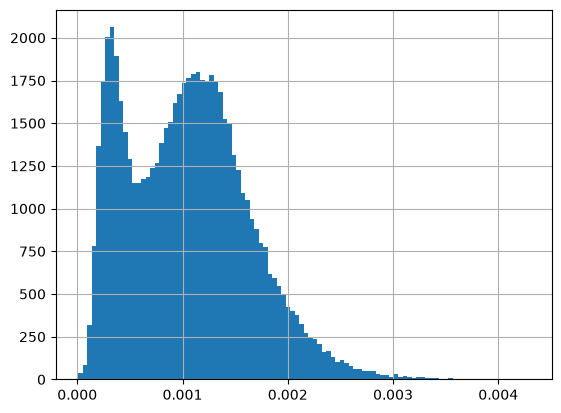

In [125]:
(
    baseline_scenario_anemia_yld_rates - intervention_anemia_yld_rates
).anemic_yld_rate.hist(bins=100)

In [126]:
zero_fort_scenario_ylds = (
    zero_fort_scenario_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
zero_fort_scenario_ylds

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  1192.154867
                               2                   905.841556
                               3                   802.686579
                               4                   667.601313
                               5                   467.432482
                                                     ...     
Male    95.0       125.000000  1                   247.528335
                               2                   241.049053
                               3                   247.010696
                               4                   239.902091
                               5                   256.461641
Length: 250, dtype: float64

In [127]:
baseline_scenario_ylds = (
    baseline_scenario_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
baseline_scenario_ylds

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  1188.943996
                               2                   903.396308
                               3                   800.570443
                               4                   665.808411
                               5                   466.165824
                                                     ...     
Male    95.0       125.000000  1                   246.790263
                               2                   240.331824
                               3                   246.282452
                               4                   239.181928
                               5                   255.660368
Length: 250, dtype: float64

In [128]:
intervention_scenarios_ylds = (
    intervention_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
intervention_scenarios_ylds

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    1112.847418
                               2                intervention     845.444755
                               3                intervention     750.418723
                               4                intervention     623.317233
                               5                intervention     436.146452
                                                                   ...     
Male    95.0       125.000000  1                intervention     229.298194
                               2                intervention     223.333732
                               3                intervention     229.023316
                               4                intervention     222.114323
                               5                intervention     236.670451
Length: 250, dtype: float64

In [129]:
(
    baseline_scenario_ylds.loc[("Female", 25, 30, 1)].mean()
    - intervention_scenarios_ylds.loc[("Female", 25, 30, 1)].mean()
)

np.float64(14508.818404622696)

In [130]:
(
    baseline_scenario_ylds.groupby(["wealth_quintile"]).sum()
    - intervention_scenarios_ylds.groupby(["scenario", "wealth_quintile"]).sum()
)

scenario      wealth_quintile
intervention  1                  318308.834317
              2                  291092.632949
              3                  282921.493473
              4                  265813.361666
              5                  242880.184112
dtype: float64

In [131]:
ylds = pd.concat(
    [
        zero_fort_scenario_ylds.rename("value").reset_index().assign(scenario="zero"),
        baseline_scenario_ylds.rename("value")
        .reset_index()
        .assign(scenario="baseline"),
        intervention_scenarios_ylds.rename("value").reset_index(),
    ],
    ignore_index=True,
)
ylds

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,1192.154867,zero
1,Female,0.0,0.019178,2,905.841556,zero
2,Female,0.0,0.019178,3,802.686579,zero
3,Female,0.0,0.019178,4,667.601313,zero
4,Female,0.0,0.019178,5,467.432482,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,229.298194,intervention
746,Male,95.0,125.000000,2,223.333732,intervention
747,Male,95.0,125.000000,3,229.023316,intervention
748,Male,95.0,125.000000,4,222.114323,intervention


In [132]:
results_dir = (
    paths.output_root(paths.NON_PREGNANT_ANEMIA_RESULTS_ROOT)
    / vehicle.lower()
    / location.lower()
)

In [133]:
path = f"{results_dir}/ylds.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
ylds.to_parquet(path)

In [134]:
zero_fort_anemia_prevalence = (
    zero_fort_scenario_anemia_by_severity["anemic"].unstack("draw").mean(axis=1)
)
zero_fort_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.812952
                               2                  0.762638
                               3                  0.751915
                               4                  0.703098
                               5                  0.661597
                                                    ...   
Male    95.0       125.000000  1                  0.620077
                               2                  0.591220
                               3                  0.579733
                               4                  0.559781
                               5                  0.533134
Length: 250, dtype: float64

In [135]:
baseline_anemia_prevalence = (
    baseline_scenario_anemia_by_severity["anemic"].unstack("draw").mean(axis=1)
)
baseline_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.811804
                               2                  0.761347
                               3                  0.750640
                               4                  0.701719
                               5                  0.660159
                                                    ...   
Male    95.0       125.000000  1                  0.618823
                               2                  0.589961
                               3                  0.578487
                               4                  0.558513
                               5                  0.531819
Length: 250, dtype: float64

In [136]:
zero_fort_anemia_cases = zero_fort_anemia_prevalence.mul(non_pregnant_pop, axis=0)
zero_fort_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  39573.439349
                               2                  32582.499715
                               3                  28522.167885
                               4                  25120.413228
                               5                  18942.494445
                                                      ...     
Male    95.0       125.000000  1                  11365.315948
                               2                  11316.082082
                               3                  11461.471222
                               4                  11672.166979
                               5                  13707.556553
Length: 250, dtype: float64

In [137]:
zero_fort_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.41940075883438993)

In [138]:
baseline_anemia_cases = baseline_anemia_prevalence.mul(non_pregnant_pop, axis=0)
baseline_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  39517.552126
                               2                  32527.340395
                               3                  28473.816947
                               4                  25071.142265
                               5                  18901.321011
                                                      ...     
Male    95.0       125.000000  1                  11342.331893
                               2                  11291.990980
                               3                  11436.837454
                               4                  11645.729678
                               5                  13673.735693
Length: 250, dtype: float64

In [139]:
baseline_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.4184036791060583)

In [140]:
baseline_anemia_cases.groupby(["wealth_quintile"]).sum() / non_pregnant_pop.groupby(
    ["wealth_quintile"]
).sum()

wealth_quintile
1    0.467112
2    0.433156
3    0.422743
4    0.399877
5    0.370967
dtype: float64

In [141]:
intervention_anemia_prevalence = (
    intervention_scenarios_anemia_by_severity["anemic"].unstack("draw").mean(axis=1)
)
intervention_anemia_prevalence

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    0.784594
                               2                intervention    0.730749
                               3                intervention    0.720431
                               4                intervention    0.669036
                               5                intervention    0.626078
                                                                  ...   
Male    95.0       125.000000  1                intervention    0.589104
                               2                intervention    0.560131
                               3                intervention    0.548957
                               4                intervention    0.528464
                               5                intervention    0.500644
Length: 250, dtype: float64

In [142]:
anemia_prevalence = pd.concat(
    [
        zero_fort_anemia_prevalence.rename("value")
        .reset_index()
        .assign(scenario="zero"),
        baseline_anemia_prevalence.rename("value")
        .reset_index()
        .assign(scenario="baseline"),
        intervention_anemia_prevalence.rename("value").reset_index(),
    ],
    ignore_index=True,
)
anemia_prevalence

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,0.812952,zero
1,Female,0.0,0.019178,2,0.762638,zero
2,Female,0.0,0.019178,3,0.751915,zero
3,Female,0.0,0.019178,4,0.703098,zero
4,Female,0.0,0.019178,5,0.661597,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,0.589104,intervention
746,Male,95.0,125.000000,2,0.560131,intervention
747,Male,95.0,125.000000,3,0.548957,intervention
748,Male,95.0,125.000000,4,0.528464,intervention


In [143]:
path = f"{results_dir}/anemia_prevalence.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
anemia_prevalence.to_parquet(path)

In [144]:
intervention_anemia_cases = intervention_anemia_prevalence.mul(non_pregnant_pop, axis=0)
intervention_anemia_cases

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    38193.043515
                               2                intervention    31220.082837
                               3                intervention    27327.915759
                               4                intervention    23903.436783
                               5                intervention    17925.524290
                                                                    ...     
Male    95.0       125.000000  1                intervention    10797.617440
                               2                intervention    10721.039853
                               3                intervention    10853.025354
                               4                intervention    11019.174415
                               5                intervention    12872.192560
Length: 250, dtype: float64

In [145]:
intervention_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.39477322062054954)

In [146]:
intervention_anemia_cases.groupby(["wealth_quintile"]).sum() / non_pregnant_pop.groupby(
    ["wealth_quintile"]
).sum()

wealth_quintile
1    0.441837
2    0.409147
3    0.399412
4    0.376961
5    0.348290
dtype: float64

In [147]:
(
    baseline_anemia_cases.groupby(["wealth_quintile"]).sum()
    - intervention_anemia_cases.groupby(["wealth_quintile"]).sum()
).map(lambda x: f"{round(x):,.0f}")

wealth_quintile
1    7,068,644
2    6,808,400
3    6,666,525
4    6,584,211
5    6,560,106
dtype: str

In [148]:
anemia_cases = pd.concat(
    [
        zero_fort_anemia_cases.rename("value").reset_index().assign(scenario="zero"),
        baseline_anemia_cases.rename("value").reset_index().assign(scenario="baseline"),
        intervention_anemia_cases.rename("value").reset_index(),
    ],
    ignore_index=True,
)
anemia_cases

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,39573.439349,zero
1,Female,0.0,0.019178,2,32582.499715,zero
2,Female,0.0,0.019178,3,28522.167885,zero
3,Female,0.0,0.019178,4,25120.413228,zero
4,Female,0.0,0.019178,5,18942.494445,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,10797.617440,intervention
746,Male,95.0,125.000000,2,10721.039853,intervention
747,Male,95.0,125.000000,3,10853.025354,intervention
748,Male,95.0,125.000000,4,11019.174415,intervention


In [149]:
path = f"{results_dir}/anemia_cases.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
anemia_cases.to_parquet(path)